Running ExG Segmentation...


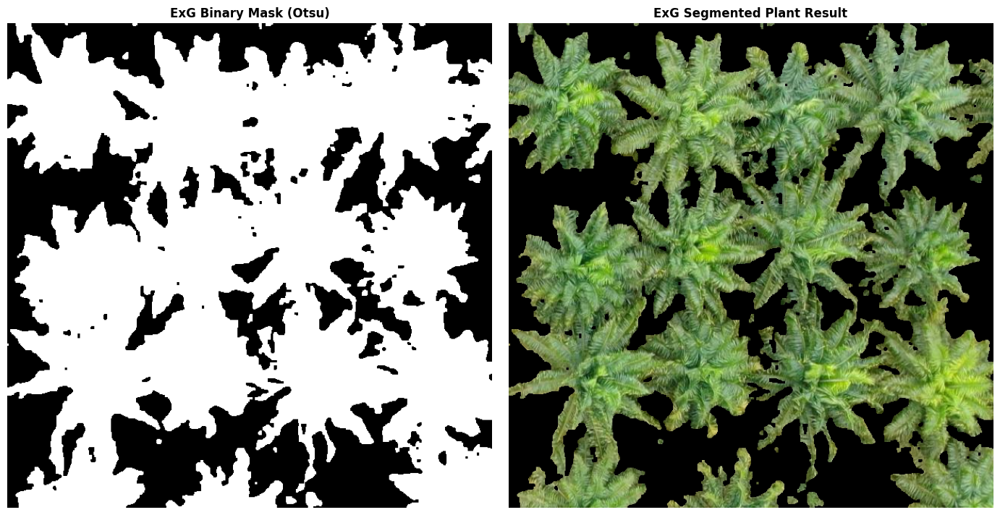

Loading CoreML model from yolo26m-krops-v0.1.mlpackage...
Running inference on ExG segmented image...
Saved 15 valid detection boxes from ExG inference.

Calculating VARI from original RGB image...

Calculating VARI for each detected oil palm...

--- Core ML Annotated Detection Image ---


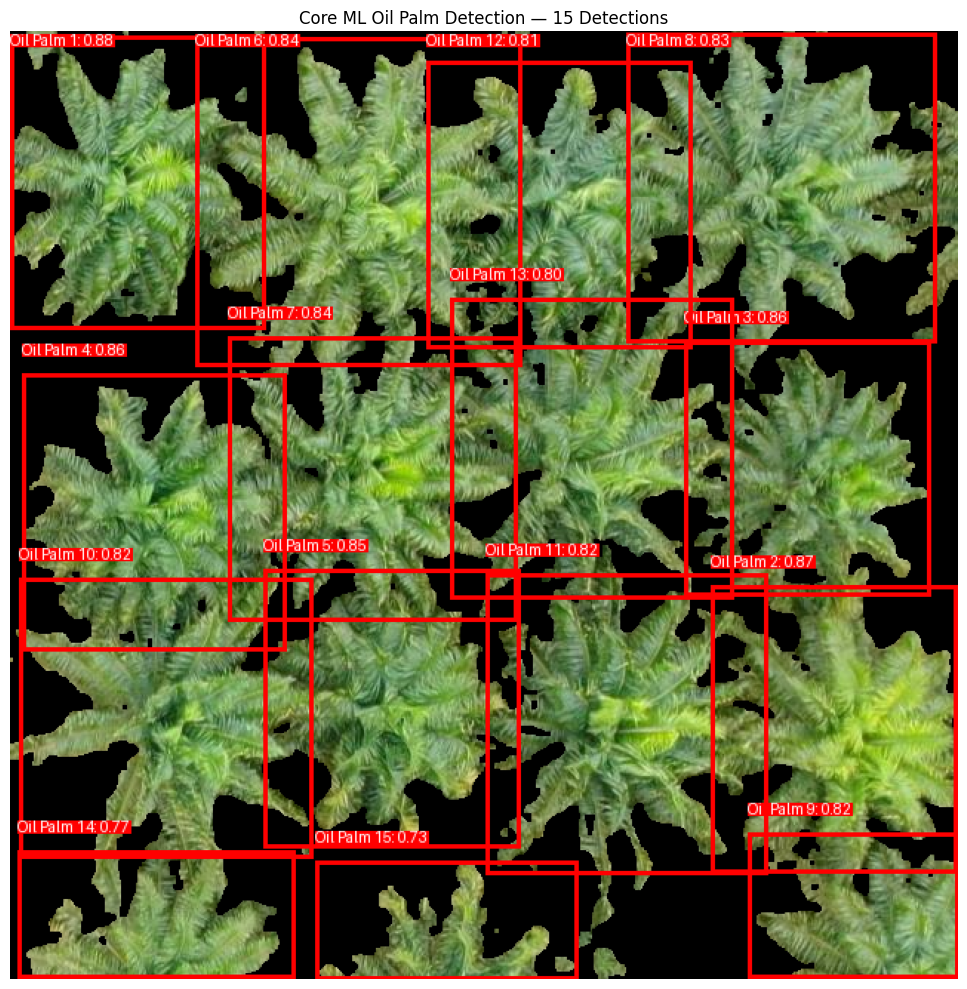


Detected trees with results: 15


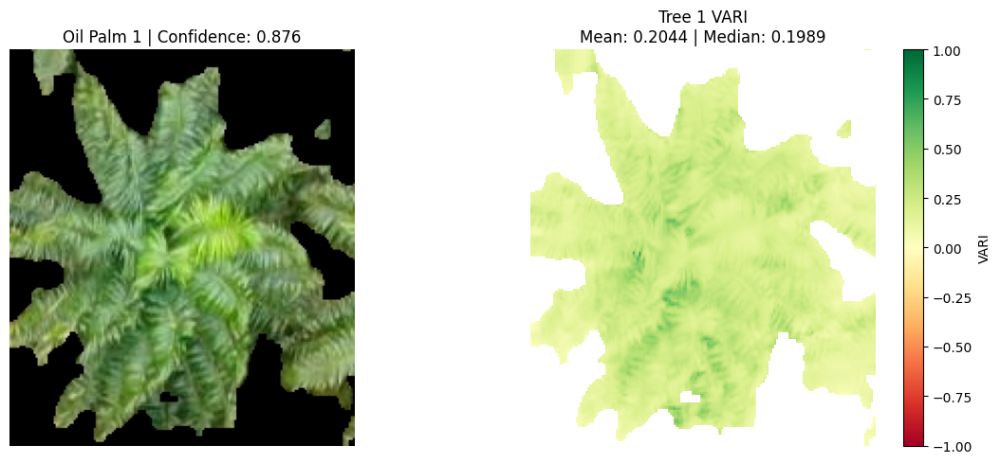

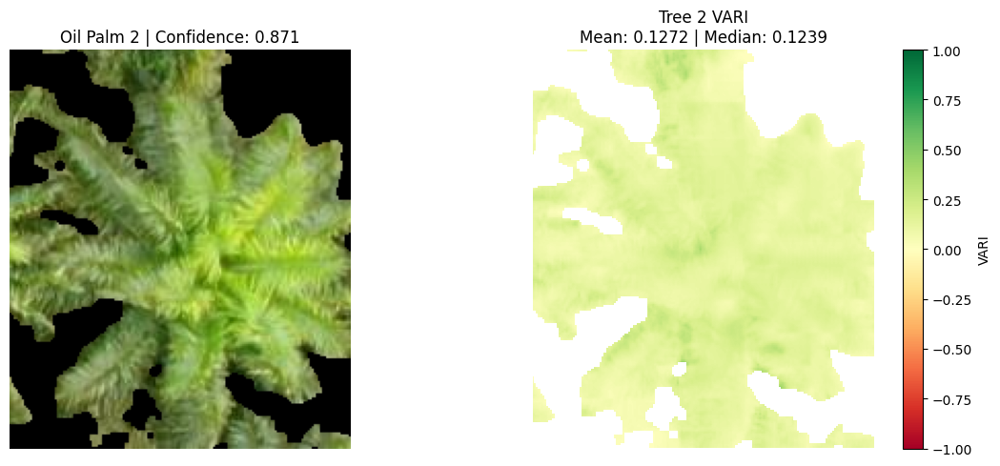

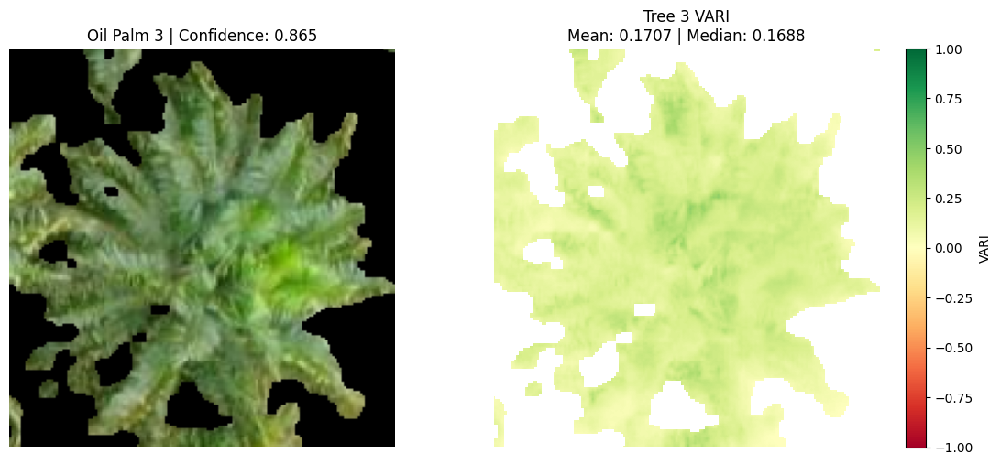

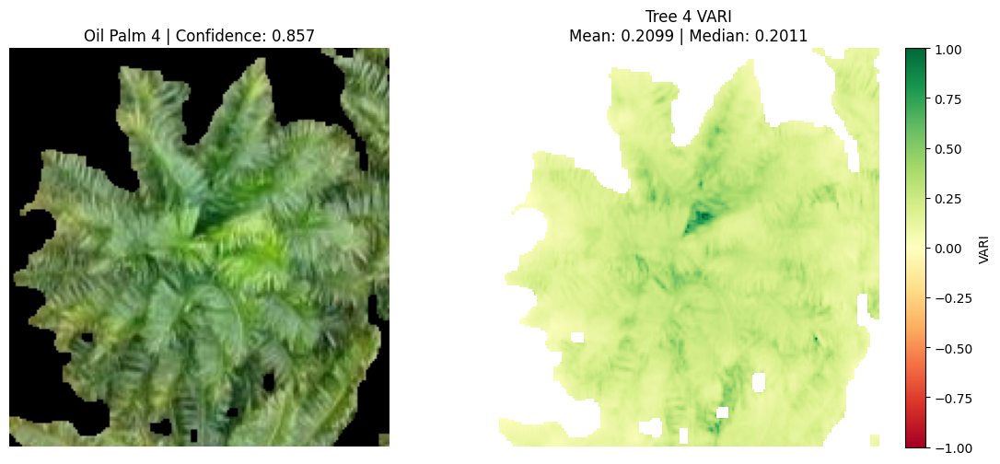

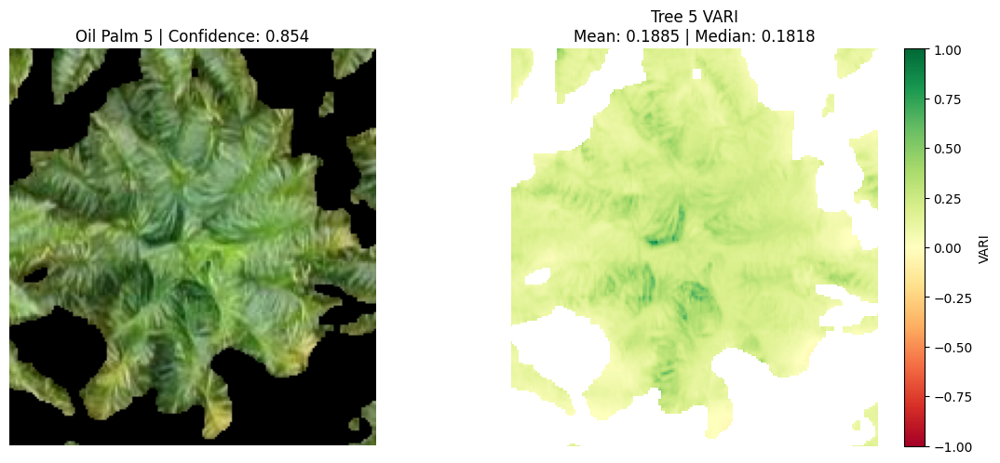

...

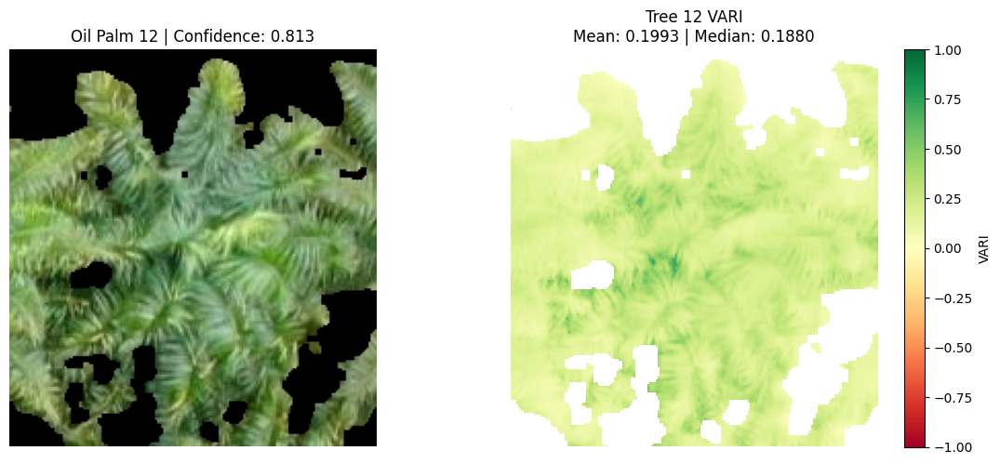

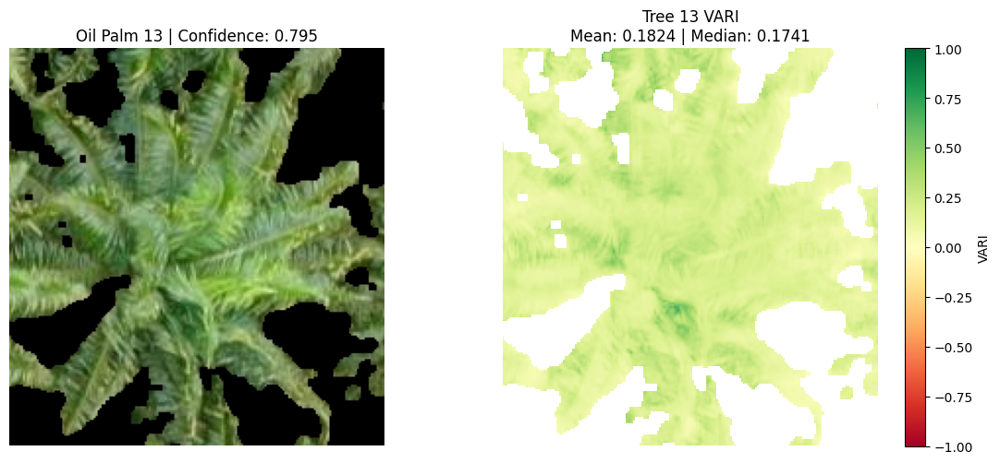

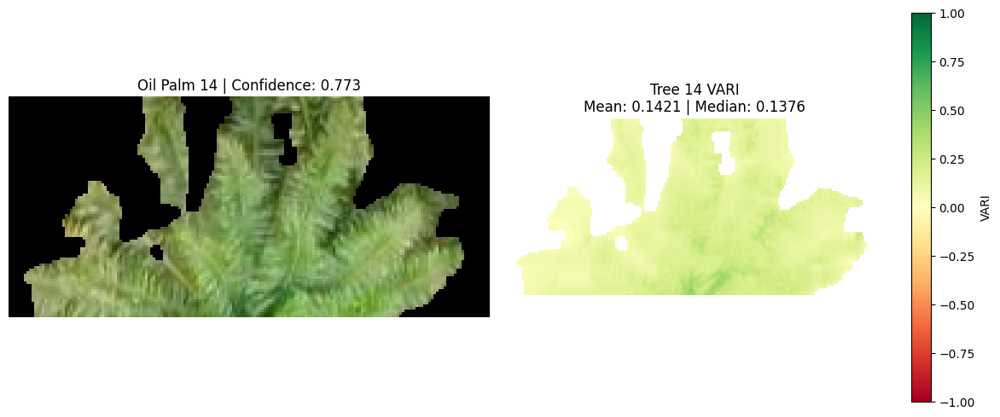

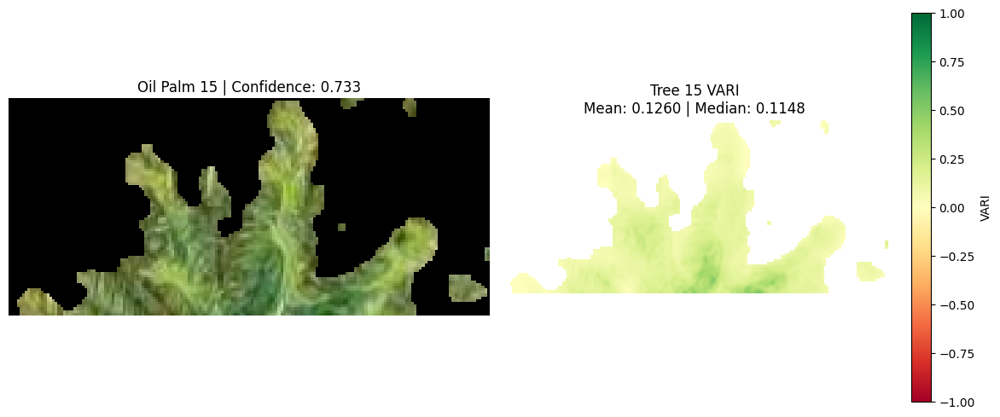

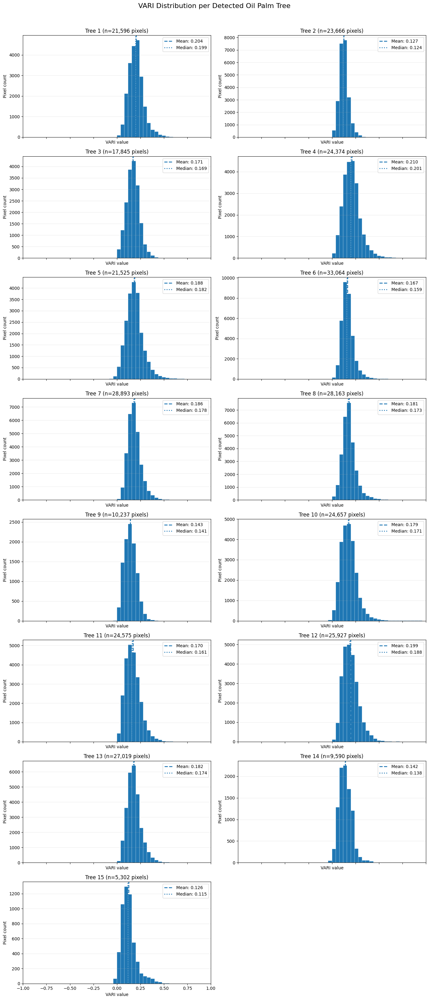

In [4]:
import cv2
import numpy as np
import coremltools as ct
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import io
import base64
from IPython.display import HTML, display

IMAGE_PATH = "DJI_15-copy_jpg.rf.947a177207587775a6d0377b1173ca20.jpg"
MODEL_PATH = "yolo26m-krops-v0.1.mlpackage"

CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.45


# --------------------------------------------------
# Helper Functions: IoU and NMS
# --------------------------------------------------

def iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    inter_w = max(0, x2 - x1)
    inter_h = max(0, y2 - y1)
    inter_area = inter_w * inter_h

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - inter_area
    return inter_area / union if union > 0 else 0


def nms(boxes, scores, iou_threshold=0.45):
    order = np.argsort(scores)[::-1]
    selected = []

    while len(order) > 0:
        i = order[0]
        selected.append(i)
        remaining = []

        for j in order[1:]:
            if iou(boxes[i], boxes[j]) <= iou_threshold:
                remaining.append(j)

        order = np.array(remaining)

    return selected


# --------------------------------------------------
# Step 1: Run ExG Segmentation
# --------------------------------------------------

def segment_vegetation_exg(image_path):
    image_bgr = cv2.imread(image_path)
    if image_bgr is None:
        raise ValueError(f"Could not load image from {image_path}. Check the path.")

    b, g, r = cv2.split(image_bgr)
    exg = (2 * g.astype(np.float32)) - r.astype(np.float32) - b.astype(np.float32)

    exg_normalized = cv2.normalize(exg, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)
    exg_uint8 = np.clip(exg_normalized, 0, 255).astype(np.uint8)

    _, binary_mask = cv2.threshold(exg_uint8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    kernel = np.ones((3, 3), np.uint8)
    binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_OPEN, kernel, iterations=1)
    binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel, iterations=1)

    segmented_plant = cv2.bitwise_and(image_bgr, image_bgr, mask=binary_mask)
    return binary_mask, segmented_plant, image_bgr

print("Running ExG Segmentation...")
exg_mask, exg_segmented_bgr, original_bgr = segment_vegetation_exg(IMAGE_PATH)
exg_rgb = cv2.cvtColor(exg_segmented_bgr, cv2.COLOR_BGR2RGB)
original_height, original_width = original_bgr.shape[:2]

# Plot ExG Inline
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(exg_mask, cmap='gray')
axes[0].set_title("ExG Binary Mask (Otsu)", fontsize=12, fontweight='bold')
axes[0].axis('off')
axes[1].imshow(exg_rgb)
axes[1].set_title("ExG Segmented Plant Result", fontsize=12, fontweight='bold')
axes[1].axis('off')
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Step 2: Run CoreML Detection on ExG Output & Save Boxes
# --------------------------------------------------

saved_boxes = []
saved_scores = []

try:
    print(f"Loading CoreML model from {MODEL_PATH}...")
    model = ct.models.MLModel(MODEL_PATH)
    input_name = list(model.input_description)[0]
    
    image_exg_pil = Image.fromarray(exg_rgb).convert("RGB")
    input_image = image_exg_pil.resize((640, 640))

    print("Running inference on ExG segmented image...")
    prediction = model.predict({input_name: input_image})
    
    output_key = list(prediction.keys())[0]
    raw = np.asarray(prediction[output_key])

    predictions = raw[0].T
    temp_boxes = []
    temp_scores = []

    for pred in predictions:
        cx, cy, w, h, confidence = pred
        if confidence < CONF_THRESHOLD:
            continue

        x1 = (cx - w / 2) / 640
        y1 = (cy - h / 2) / 640
        x2 = (cx + w / 2) / 640
        y2 = (cy + h / 2) / 640

        temp_boxes.append([max(0, min(1, x1)), max(0, min(1, y1)), max(0, min(1, x2)), max(0, min(1, y2))])
        temp_scores.append(float(confidence))

    if temp_boxes:
        selected = nms(temp_boxes, temp_scores, IOU_THRESHOLD)
        saved_boxes = [temp_boxes[i] for i in selected]
        saved_scores = [temp_scores[i] for i in selected]

    print(f"Saved {len(saved_boxes)} valid detection boxes from ExG inference.")

except Exception as e:
    print(f"\n[Execution Note]: {e}")
    print("Tip: CoreML native prediction (`model.predict()`) requires running inside a macOS environment.")


# --------------------------------------------------
# Step 3: Calculate VARI from Original RGB Image
# --------------------------------------------------

print("\nCalculating VARI from original RGB image...")

# OpenCV loads the original image in BGR order
b_original, g_original, r_original = cv2.split(original_bgr)

# Convert to float to avoid integer arithmetic issues
b_f = b_original.astype(np.float32)
g_f = g_original.astype(np.float32)
r_f = r_original.astype(np.float32)

# VARI = (G - R) / (G + R - B)
denominator = g_f + r_f - b_f

vari_map = np.full(denominator.shape, np.nan, dtype=np.float32)

valid_pixels = denominator != 0

np.divide(
    g_f - r_f,
    denominator,
    out=vari_map,
    where=valid_pixels
)

# --------------------------------------------------
# Step 4: Calculate VARI for Each Detected Tree
# --------------------------------------------------

print("\nCalculating VARI for each detected oil palm...")

tree_results = []

# Use original image for the crops
original_rgb = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)

for idx, (box, score) in enumerate(zip(saved_boxes, saved_scores)):

    # Bounding box coordinates are normalized to [0, 1]
    x1, y1, x2, y2 = box

    # Convert to original image pixel coordinates
    px1 = max(0, int(x1 * original_width))
    py1 = max(0, int(y1 * original_height))
    px2 = min(original_width, int(x2 * original_width))
    py2 = min(original_height, int(y2 * original_height))

    if px2 <= px1 or py2 <= py1:
        continue

    # Crop the VARI map and ExG mask for this tree
    tree_vari = vari_map[py1:py2, px1:px2]
    tree_mask = exg_mask[py1:py2, px1:px2]

    # Only use pixels identified as vegetation by ExG
    valid_tree_pixels = (
        (tree_mask > 0) &
        np.isfinite(tree_vari)
    )

    values = tree_vari[valid_tree_pixels]

    if values.size == 0:
        mean_vari = np.nan
        median_vari = np.nan
        std_vari = np.nan
    else:
        mean_vari = float(np.mean(values))
        median_vari = float(np.median(values))
        std_vari = float(np.std(values))

    tree_results.append({
        "tree_id": idx + 1,
        "confidence": float(score),
        "bbox": (px1, py1, px2, py2),
        "vegetation_pixels": int(values.size),
        "mean_vari": mean_vari,
        "median_vari": median_vari,
        "std_vari": std_vari,
    })

# --------------------------------------------------
# Step 5: Display Annotated Core ML Detection Image
# --------------------------------------------------

print("\n--- Core ML Annotated Detection Image ---")

# Start with the ORIGINAL RGB image, not the ExG-segmented image
annotated_image = Image.fromarray(exg_rgb)
draw = ImageDraw.Draw(annotated_image)

for idx, (box, score) in enumerate(zip(saved_boxes, saved_scores)):

    x1, y1, x2, y2 = box

    # Convert normalized coordinates to original image coordinates
    px1 = max(0, int(x1 * original_width))
    py1 = max(0, int(y1 * original_height))
    px2 = min(original_width, int(x2 * original_width))
    py2 = min(original_height, int(y2 * original_height))

    # Draw bounding box
    draw.rectangle(
        [px1, py1, px2, py2],
        outline="red",
        width=3
    )

    # Label and confidence score
    label = f"Oil Palm {idx + 1}: {score:.2f}"

    # Draw label above the box where possible
    text_y = max(0, py1 - 22)

    # Add a background for label readability
    text_bbox = draw.textbbox((px1, text_y), label)
    draw.rectangle(text_bbox, fill="red")

    draw.text(
        (px1, text_y),
        label,
        fill="white"
    )

# Display the annotated image
plt.figure(figsize=(16, 10))
plt.imshow(annotated_image)
plt.title(
    f"Core ML Oil Palm Detection — {len(saved_boxes)} Detections"
)
plt.axis("off")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# Step 6: Visualize VARI for Each Detected Tree
# --------------------------------------------------

print(f"\nDetected trees with results: {len(tree_results)}")

for result in tree_results:

    tree_id = result["tree_id"]
    px1, py1, px2, py2 = result["bbox"]

    # Crop original RGB image and corresponding VARI map
    tree_rgb = exg_rgb[py1:py2, px1:px2]
    tree_vari = vari_map[py1:py2, px1:px2]
    tree_mask = exg_mask[py1:py2, px1:px2]

    # Hide pixels outside the vegetation mask
    tree_vari_display = np.where(
        (tree_mask > 0) & np.isfinite(tree_vari),
        tree_vari,
        np.nan
    )

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(tree_rgb)
    axes[0].set_title(
        f"Oil Palm {tree_id} | Confidence: {result['confidence']:.3f}"
    )
    axes[0].axis("off")

    im = axes[1].imshow(
        tree_vari_display,
        cmap="RdYlGn",
        vmin=-1,
        vmax=1
    )

    axes[1].set_title(
        f"Tree {tree_id} VARI\n"
        f"Mean: {result['mean_vari']:.4f} | "
        f"Median: {result['median_vari']:.4f}"
    )
    axes[1].axis("off")

    fig.colorbar(im, ax=axes[1], label="VARI")
    plt.tight_layout()
    plt.show()

# ==========================================
# STEP 7: VARI DISTRIBUTION PER DETECTED TREE
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

tree_vari_distributions = []

for idx, box in enumerate(saved_boxes):
    x1, y1, x2, y2 = box

    # Convert normalized bounding box to pixel coordinates
    px1 = max(0, int(x1 * original_width))
    py1 = max(0, int(y1 * original_height))
    px2 = min(original_width, int(x2 * original_width))
    py2 = min(original_height, int(y2 * original_height))

    # Crop VARI map and vegetation mask
    tree_vari = vari_map[py1:py2, px1:px2]
    tree_mask = exg_mask[py1:py2, px1:px2]

    # Include only vegetation pixels with finite VARI values
    valid_pixels = (
        (tree_mask > 0) &
        np.isfinite(tree_vari)
    )

    values = tree_vari[valid_pixels]

    if values.size == 0:
        print(f"Tree {idx + 1}: No valid VARI pixels.")
        continue

    tree_vari_distributions.append({
        "tree_id": idx + 1,
        "values": values,
        "mean": np.mean(values),
        "median": np.median(values),
        "std": np.std(values),
    })


# ==========================================
# PLOT: HISTOGRAM FOR EACH TREE
# ==========================================

number_of_trees = len(tree_vari_distributions)

if number_of_trees == 0:
    print("No trees contain valid VARI pixels.")
else:
    cols = 2
    rows = (number_of_trees + cols - 1) // cols

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(14, 4 * rows),
        sharex=True,
        sharey=False,
        squeeze=False,
    )

    axes = axes.flatten()

    for ax, result in zip(axes, tree_vari_distributions):
        values = result["values"]

        ax.hist(
            values,
            bins=50,
            range=(-1, 1),
            edgecolor="white",
            linewidth=0.3,
        )

        ax.axvline(
            result["mean"],
            linestyle="--",
            linewidth=2,
            label=f"Mean: {result['mean']:.3f}",
        )

        ax.axvline(
            result["median"],
            linestyle=":",
            linewidth=2,
            label=f"Median: {result['median']:.3f}",
        )

        ax.set_title(
            f"Tree {result['tree_id']} "
            f"(n={len(values):,} pixels)"
        )
        ax.set_xlabel("VARI value")
        ax.set_ylabel("Pixel count")
        ax.set_xlim(-1, 1)
        ax.grid(axis="y", alpha=0.25)
        ax.legend()

    # Hide unused subplot axes
    for ax in axes[number_of_trees:]:
        ax.set_visible(False)

    fig.suptitle(
        "VARI Distribution per Detected Oil Palm Tree",
        fontsize=16,
        y=1.01,
    )

    plt.tight_layout()
    plt.show()    

Running ExG Segmentation...


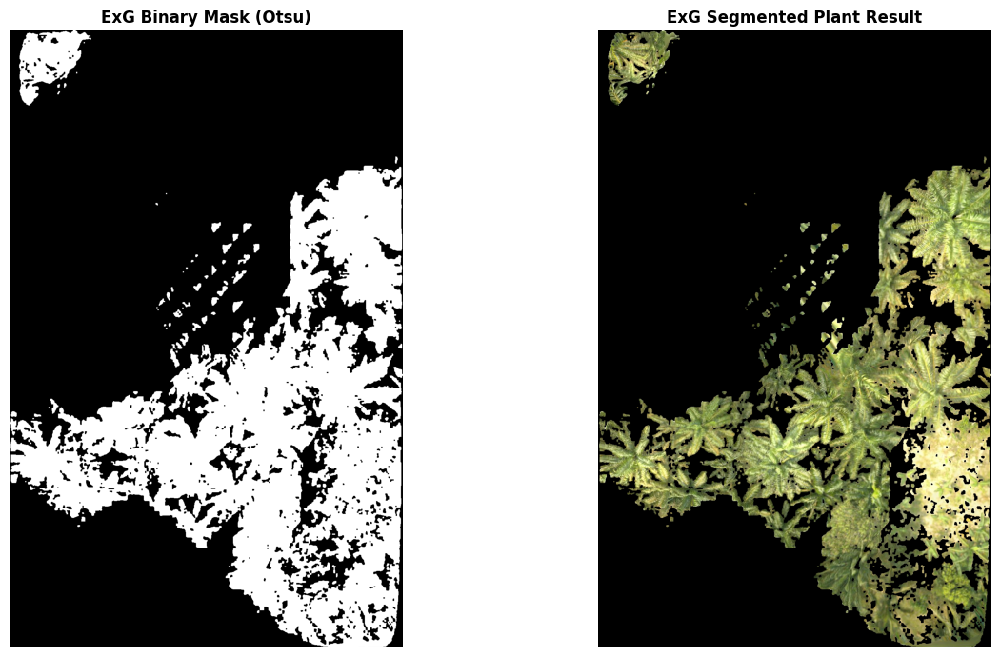

Loading CoreML model from yolo26m-krops-v0.1.mlpackage...
Running inference on ExG segmented image...
Saved 10 valid detection boxes from ExG inference.

Calculating VARI from original RGB image...

Calculating VARI for each detected oil palm...

--- Core ML Annotated Detection Image ---


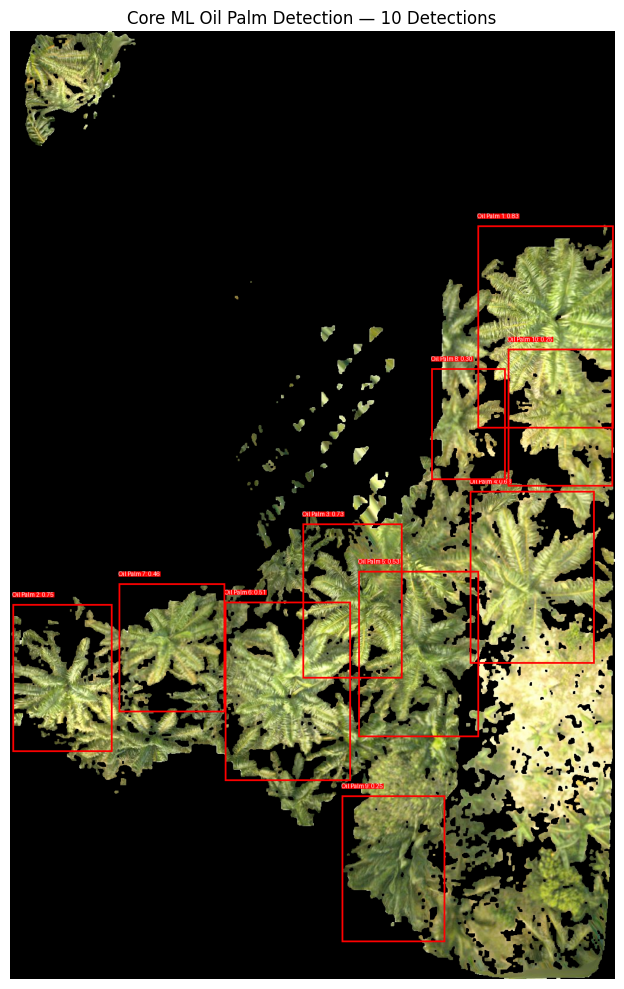


Detected trees with results: 10


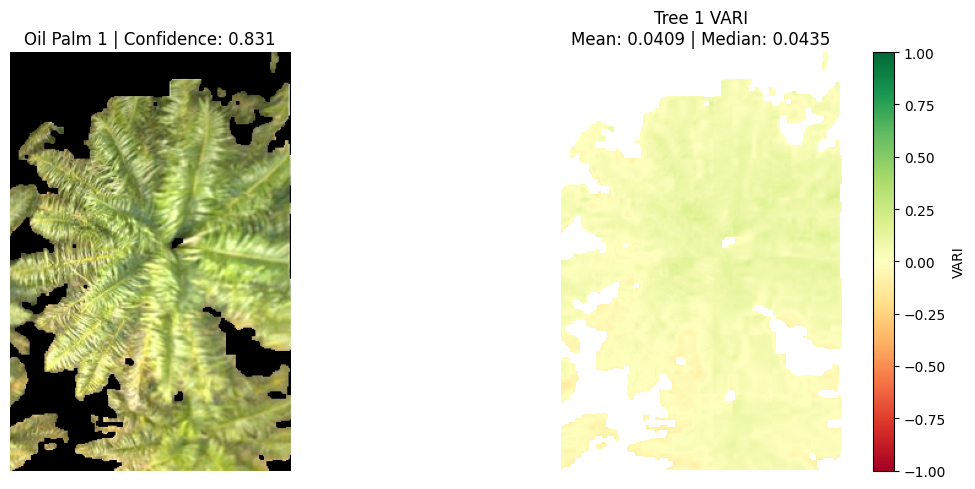

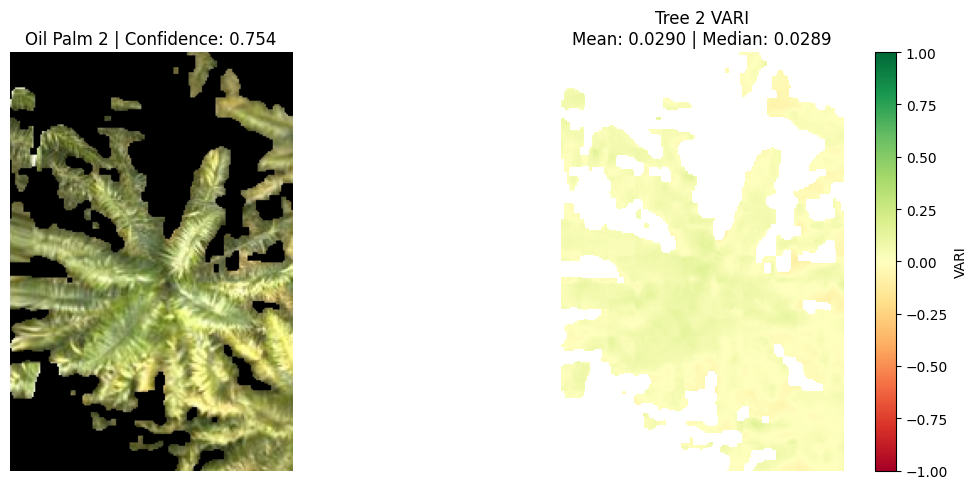

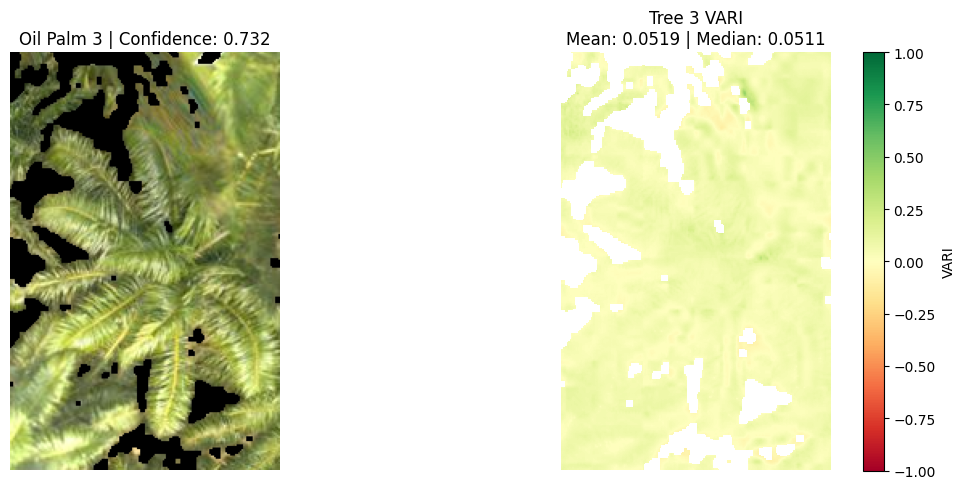

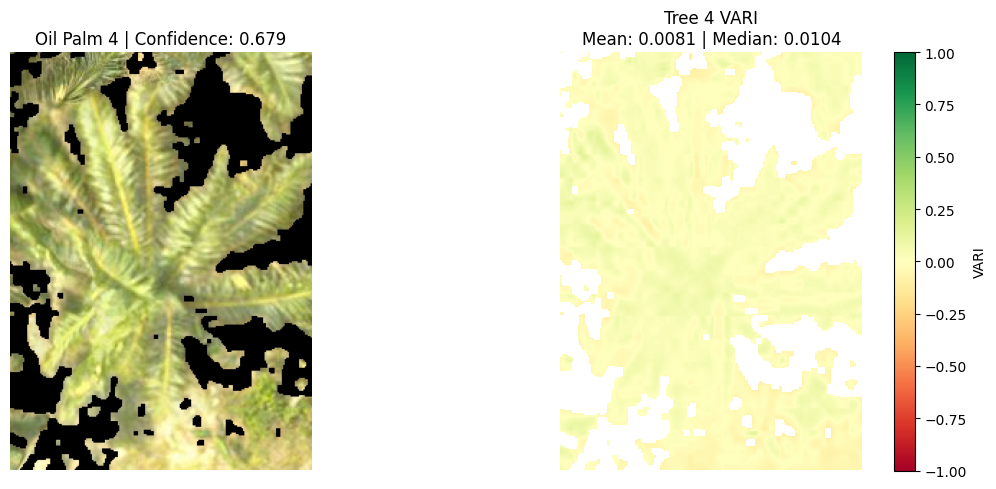

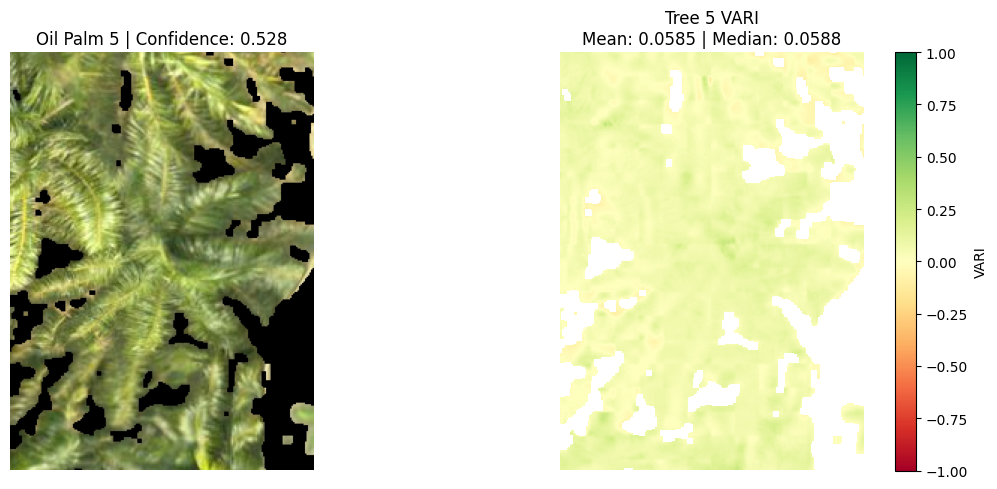

...

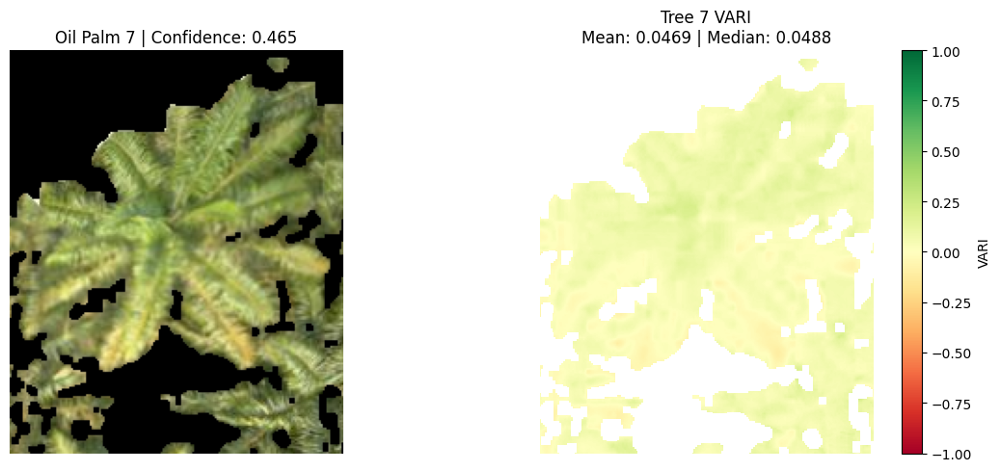

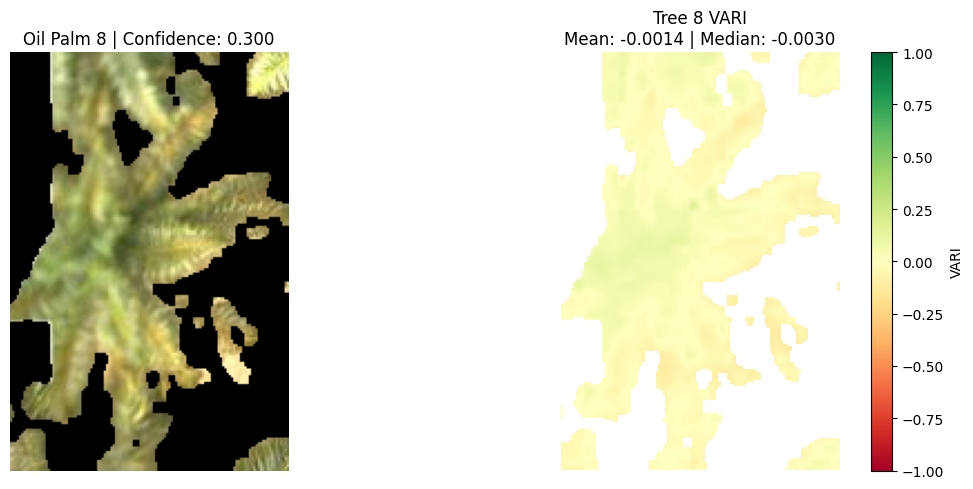

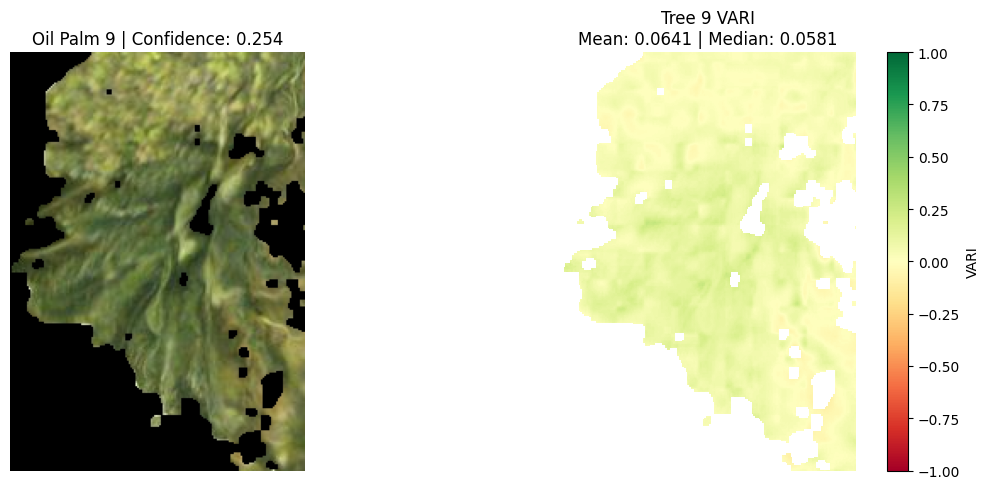

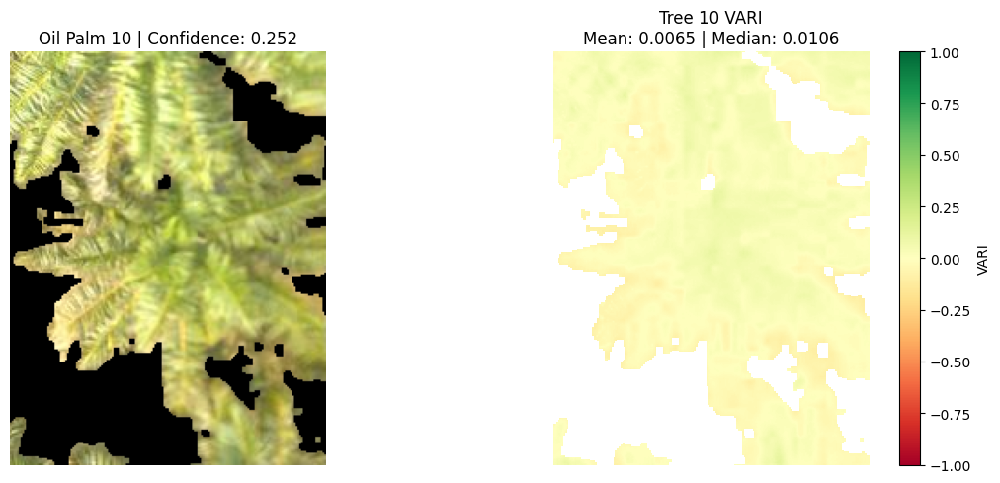

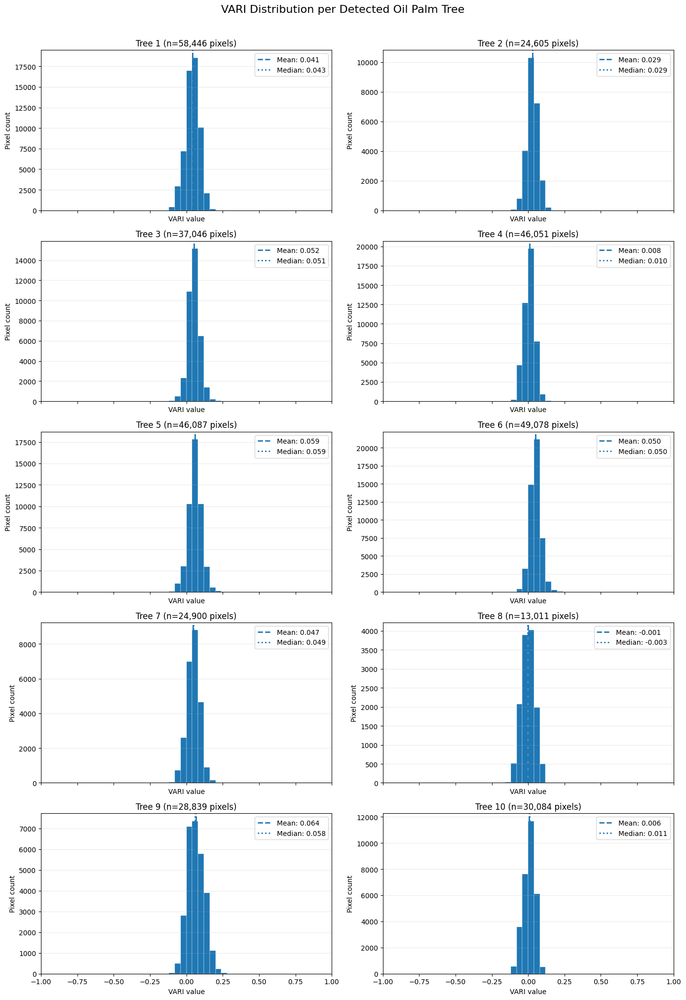

In [7]:
import cv2
import numpy as np
import coremltools as ct
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import io
import base64
from IPython.display import HTML, display

IMAGE_PATH = "webodm_last_image.jpeg"
MODEL_PATH = "yolo26m-krops-v0.1.mlpackage"

CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.45


# --------------------------------------------------
# Helper Functions: IoU and NMS
# --------------------------------------------------

def iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    inter_w = max(0, x2 - x1)
    inter_h = max(0, y2 - y1)
    inter_area = inter_w * inter_h

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - inter_area
    return inter_area / union if union > 0 else 0


def nms(boxes, scores, iou_threshold=0.45):
    order = np.argsort(scores)[::-1]
    selected = []

    while len(order) > 0:
        i = order[0]
        selected.append(i)
        remaining = []

        for j in order[1:]:
            if iou(boxes[i], boxes[j]) <= iou_threshold:
                remaining.append(j)

        order = np.array(remaining)

    return selected


# --------------------------------------------------
# Step 1: Run ExG Segmentation
# --------------------------------------------------

def segment_vegetation_exg(image_path):
    image_bgr = cv2.imread(image_path)
    if image_bgr is None:
        raise ValueError(f"Could not load image from {image_path}. Check the path.")

    b, g, r = cv2.split(image_bgr)
    exg = (2 * g.astype(np.float32)) - r.astype(np.float32) - b.astype(np.float32)

    exg_normalized = cv2.normalize(exg, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)
    exg_uint8 = np.clip(exg_normalized, 0, 255).astype(np.uint8)

    _, binary_mask = cv2.threshold(exg_uint8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    kernel = np.ones((3, 3), np.uint8)
    binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_OPEN, kernel, iterations=1)
    binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel, iterations=1)

    segmented_plant = cv2.bitwise_and(image_bgr, image_bgr, mask=binary_mask)
    return binary_mask, segmented_plant, image_bgr

print("Running ExG Segmentation...")
exg_mask, exg_segmented_bgr, original_bgr = segment_vegetation_exg(IMAGE_PATH)
exg_rgb = cv2.cvtColor(exg_segmented_bgr, cv2.COLOR_BGR2RGB)
original_height, original_width = original_bgr.shape[:2]

# Plot ExG Inline
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(exg_mask, cmap='gray')
axes[0].set_title("ExG Binary Mask (Otsu)", fontsize=12, fontweight='bold')
axes[0].axis('off')
axes[1].imshow(exg_rgb)
axes[1].set_title("ExG Segmented Plant Result", fontsize=12, fontweight='bold')
axes[1].axis('off')
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Step 2: Run CoreML Detection on ExG Output & Save Boxes
# --------------------------------------------------

saved_boxes = []
saved_scores = []

try:
    print(f"Loading CoreML model from {MODEL_PATH}...")
    model = ct.models.MLModel(MODEL_PATH)
    input_name = list(model.input_description)[0]
    
    image_exg_pil = Image.fromarray(exg_rgb).convert("RGB")
    input_image = image_exg_pil.resize((640, 640))

    print("Running inference on ExG segmented image...")
    prediction = model.predict({input_name: input_image})
    
    output_key = list(prediction.keys())[0]
    raw = np.asarray(prediction[output_key])

    predictions = raw[0].T
    temp_boxes = []
    temp_scores = []

    for pred in predictions:
        cx, cy, w, h, confidence = pred
        if confidence < CONF_THRESHOLD:
            continue

        x1 = (cx - w / 2) / 640
        y1 = (cy - h / 2) / 640
        x2 = (cx + w / 2) / 640
        y2 = (cy + h / 2) / 640

        temp_boxes.append([max(0, min(1, x1)), max(0, min(1, y1)), max(0, min(1, x2)), max(0, min(1, y2))])
        temp_scores.append(float(confidence))

    if temp_boxes:
        selected = nms(temp_boxes, temp_scores, IOU_THRESHOLD)
        saved_boxes = [temp_boxes[i] for i in selected]
        saved_scores = [temp_scores[i] for i in selected]

    print(f"Saved {len(saved_boxes)} valid detection boxes from ExG inference.")

except Exception as e:
    print(f"\n[Execution Note]: {e}")
    print("Tip: CoreML native prediction (`model.predict()`) requires running inside a macOS environment.")


# --------------------------------------------------
# Step 3: Calculate VARI from Original RGB Image
# --------------------------------------------------

print("\nCalculating VARI from original RGB image...")

# OpenCV loads the original image in BGR order
b_original, g_original, r_original = cv2.split(original_bgr)

# Convert to float to avoid integer arithmetic issues
b_f = b_original.astype(np.float32)
g_f = g_original.astype(np.float32)
r_f = r_original.astype(np.float32)

# VARI = (G - R) / (G + R - B)
denominator = g_f + r_f - b_f

vari_map = np.full(denominator.shape, np.nan, dtype=np.float32)

valid_pixels = denominator != 0

np.divide(
    g_f - r_f,
    denominator,
    out=vari_map,
    where=valid_pixels
)

# --------------------------------------------------
# Step 4: Calculate VARI for Each Detected Tree
# --------------------------------------------------

print("\nCalculating VARI for each detected oil palm...")

tree_results = []

# Use original image for the crops
original_rgb = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)

for idx, (box, score) in enumerate(zip(saved_boxes, saved_scores)):

    # Bounding box coordinates are normalized to [0, 1]
    x1, y1, x2, y2 = box

    # Convert to original image pixel coordinates
    px1 = max(0, int(x1 * original_width))
    py1 = max(0, int(y1 * original_height))
    px2 = min(original_width, int(x2 * original_width))
    py2 = min(original_height, int(y2 * original_height))

    if px2 <= px1 or py2 <= py1:
        continue

    # Crop the VARI map and ExG mask for this tree
    tree_vari = vari_map[py1:py2, px1:px2]
    tree_mask = exg_mask[py1:py2, px1:px2]

    # Only use pixels identified as vegetation by ExG
    valid_tree_pixels = (
        (tree_mask > 0) &
        np.isfinite(tree_vari)
    )

    values = tree_vari[valid_tree_pixels]

    if values.size == 0:
        mean_vari = np.nan
        median_vari = np.nan
        std_vari = np.nan
    else:
        mean_vari = float(np.mean(values))
        median_vari = float(np.median(values))
        std_vari = float(np.std(values))

    tree_results.append({
        "tree_id": idx + 1,
        "confidence": float(score),
        "bbox": (px1, py1, px2, py2),
        "vegetation_pixels": int(values.size),
        "mean_vari": mean_vari,
        "median_vari": median_vari,
        "std_vari": std_vari,
    })

# --------------------------------------------------
# Step 5: Display Annotated Core ML Detection Image
# --------------------------------------------------

print("\n--- Core ML Annotated Detection Image ---")

# Start with the ORIGINAL RGB image, not the ExG-segmented image
annotated_image = Image.fromarray(exg_rgb)
draw = ImageDraw.Draw(annotated_image)

for idx, (box, score) in enumerate(zip(saved_boxes, saved_scores)):

    x1, y1, x2, y2 = box

    # Convert normalized coordinates to original image coordinates
    px1 = max(0, int(x1 * original_width))
    py1 = max(0, int(y1 * original_height))
    px2 = min(original_width, int(x2 * original_width))
    py2 = min(original_height, int(y2 * original_height))

    # Draw bounding box
    draw.rectangle(
        [px1, py1, px2, py2],
        outline="red",
        width=3
    )

    # Label and confidence score
    label = f"Oil Palm {idx + 1}: {score:.2f}"

    # Draw label above the box where possible
    text_y = max(0, py1 - 22)

    # Add a background for label readability
    text_bbox = draw.textbbox((px1, text_y), label)
    draw.rectangle(text_bbox, fill="red")

    draw.text(
        (px1, text_y),
        label,
        fill="white"
    )

# Display the annotated image
plt.figure(figsize=(16, 10))
plt.imshow(annotated_image)
plt.title(
    f"Core ML Oil Palm Detection — {len(saved_boxes)} Detections"
)
plt.axis("off")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# Step 6: Visualize VARI for Each Detected Tree
# --------------------------------------------------

print(f"\nDetected trees with results: {len(tree_results)}")

for result in tree_results:

    tree_id = result["tree_id"]
    px1, py1, px2, py2 = result["bbox"]

    # Crop original RGB image and corresponding VARI map
    tree_rgb = exg_rgb[py1:py2, px1:px2]
    tree_vari = vari_map[py1:py2, px1:px2]
    tree_mask = exg_mask[py1:py2, px1:px2]

    # Hide pixels outside the vegetation mask
    tree_vari_display = np.where(
        (tree_mask > 0) & np.isfinite(tree_vari),
        tree_vari,
        np.nan
    )

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(tree_rgb)
    axes[0].set_title(
        f"Oil Palm {tree_id} | Confidence: {result['confidence']:.3f}"
    )
    axes[0].axis("off")

    im = axes[1].imshow(
        tree_vari_display,
        cmap="RdYlGn",
        vmin=-1,
        vmax=1
    )

    axes[1].set_title(
        f"Tree {tree_id} VARI\n"
        f"Mean: {result['mean_vari']:.4f} | "
        f"Median: {result['median_vari']:.4f}"
    )
    axes[1].axis("off")

    fig.colorbar(im, ax=axes[1], label="VARI")
    plt.tight_layout()
    plt.show()

# ==========================================
# STEP 7: VARI DISTRIBUTION PER DETECTED TREE
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

tree_vari_distributions = []

for idx, box in enumerate(saved_boxes):
    x1, y1, x2, y2 = box

    # Convert normalized bounding box to pixel coordinates
    px1 = max(0, int(x1 * original_width))
    py1 = max(0, int(y1 * original_height))
    px2 = min(original_width, int(x2 * original_width))
    py2 = min(original_height, int(y2 * original_height))

    # Crop VARI map and vegetation mask
    tree_vari = vari_map[py1:py2, px1:px2]
    tree_mask = exg_mask[py1:py2, px1:px2]

    # Include only vegetation pixels with finite VARI values
    valid_pixels = (
        (tree_mask > 0) &
        np.isfinite(tree_vari)
    )

    values = tree_vari[valid_pixels]

    if values.size == 0:
        print(f"Tree {idx + 1}: No valid VARI pixels.")
        continue

    tree_vari_distributions.append({
        "tree_id": idx + 1,
        "values": values,
        "mean": np.mean(values),
        "median": np.median(values),
        "std": np.std(values),
    })


# ==========================================
# PLOT: HISTOGRAM FOR EACH TREE
# ==========================================

number_of_trees = len(tree_vari_distributions)

if number_of_trees == 0:
    print("No trees contain valid VARI pixels.")
else:
    cols = 2
    rows = (number_of_trees + cols - 1) // cols

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(14, 4 * rows),
        sharex=True,
        sharey=False,
        squeeze=False,
    )

    axes = axes.flatten()

    for ax, result in zip(axes, tree_vari_distributions):
        values = result["values"]

        ax.hist(
            values,
            bins=50,
            range=(-1, 1),
            edgecolor="white",
            linewidth=0.3,
        )

        ax.axvline(
            result["mean"],
            linestyle="--",
            linewidth=2,
            label=f"Mean: {result['mean']:.3f}",
        )

        ax.axvline(
            result["median"],
            linestyle=":",
            linewidth=2,
            label=f"Median: {result['median']:.3f}",
        )

        ax.set_title(
            f"Tree {result['tree_id']} "
            f"(n={len(values):,} pixels)"
        )
        ax.set_xlabel("VARI value")
        ax.set_ylabel("Pixel count")
        ax.set_xlim(-1, 1)
        ax.grid(axis="y", alpha=0.25)
        ax.legend()

    # Hide unused subplot axes
    for ax in axes[number_of_trees:]:
        ax.set_visible(False)

    fig.suptitle(
        "VARI Distribution per Detected Oil Palm Tree",
        fontsize=16,
        y=1.01,
    )

    plt.tight_layout()
    plt.show()    

Running ExG Segmentation...


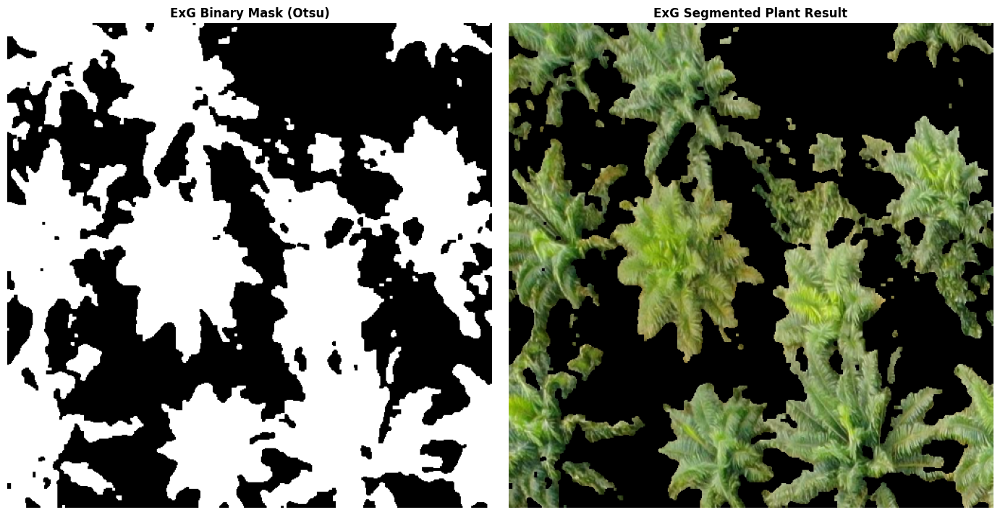

Loading CoreML model from yolo26m-krops-v0.1.mlpackage...
Running inference on ExG segmented image...
Saved 10 valid detection boxes from ExG inference.

Calculating VARI from original RGB image...

Calculating VARI for each detected oil palm...

--- Core ML Annotated Detection Image ---


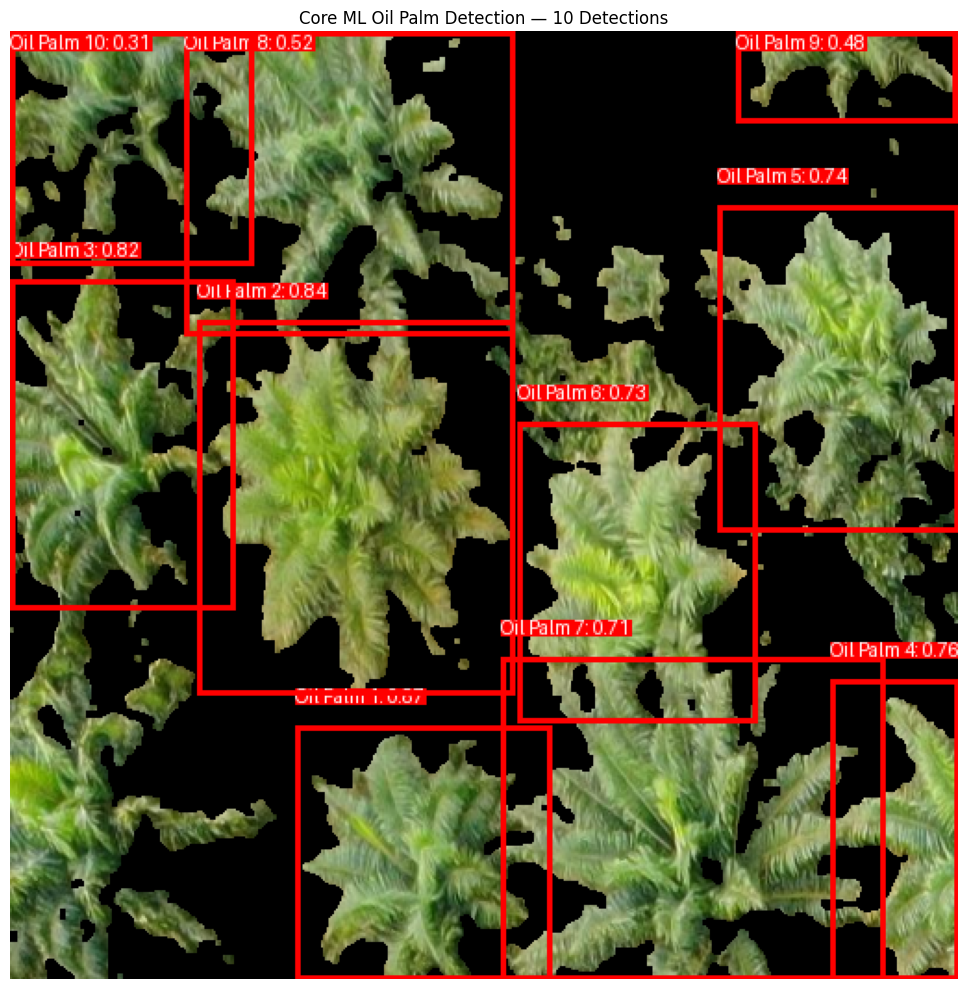


Detected trees with results: 10


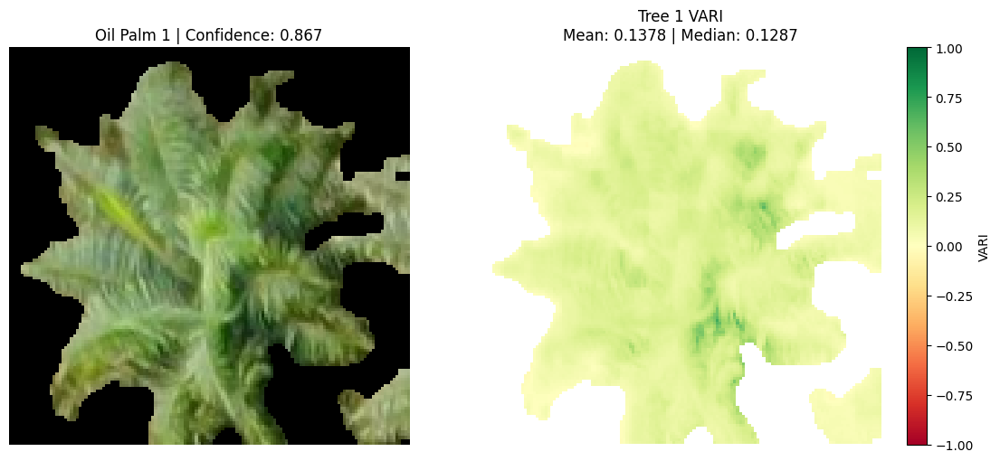

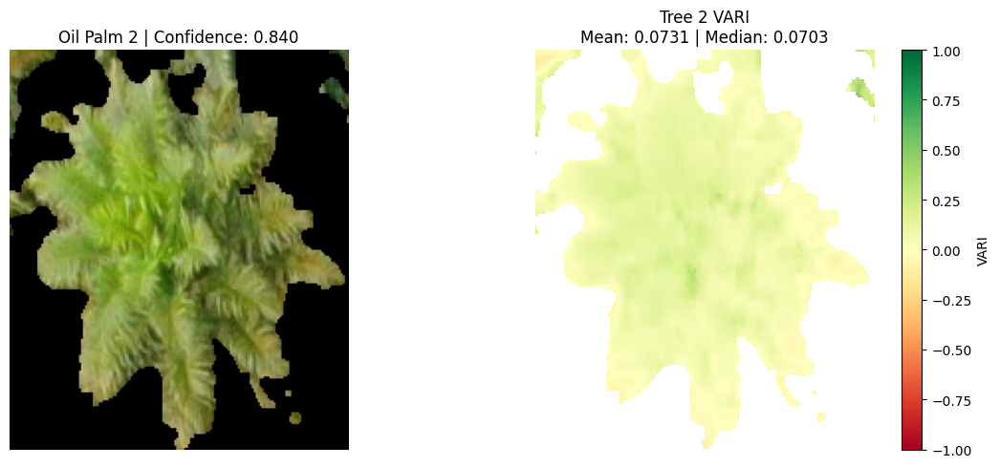

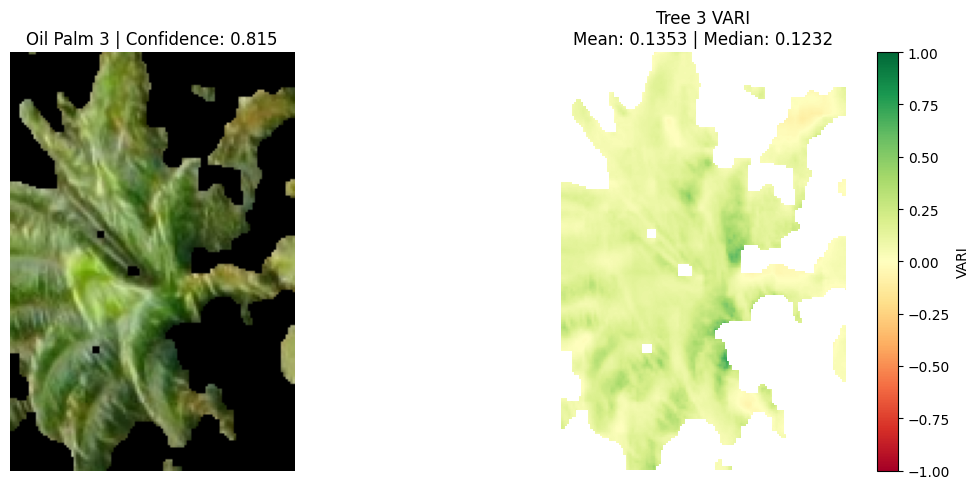

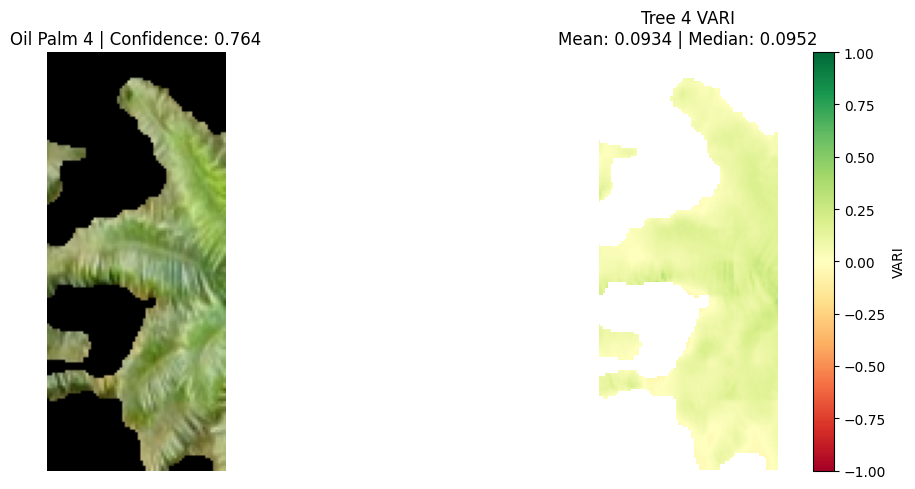

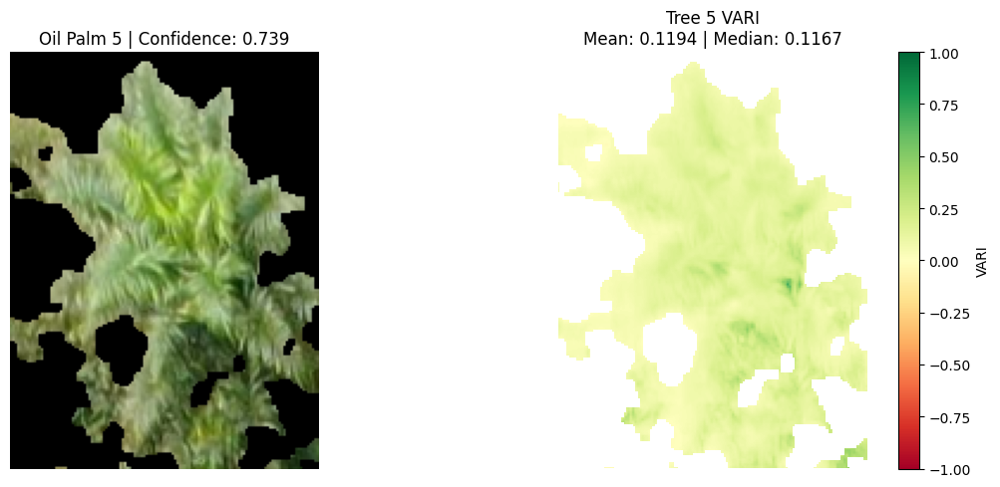

...

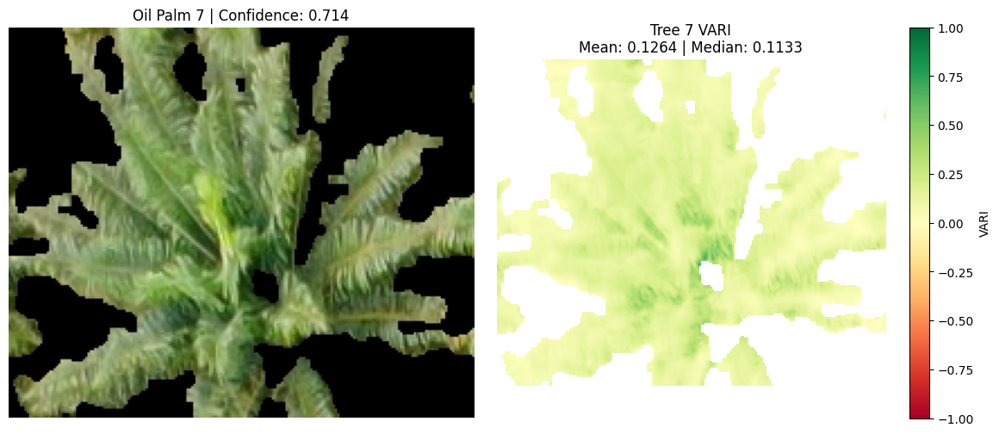

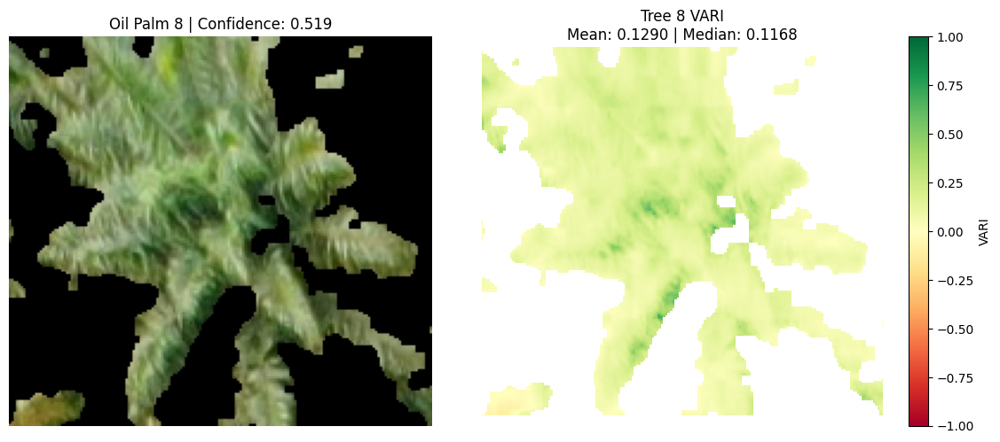

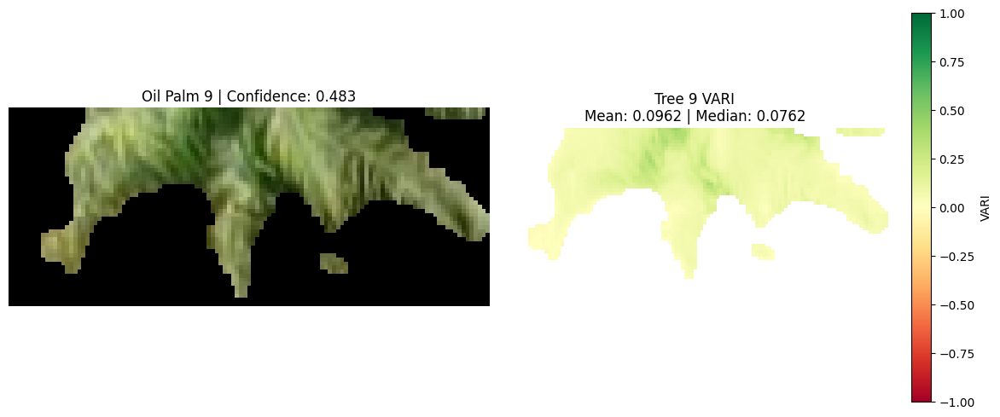

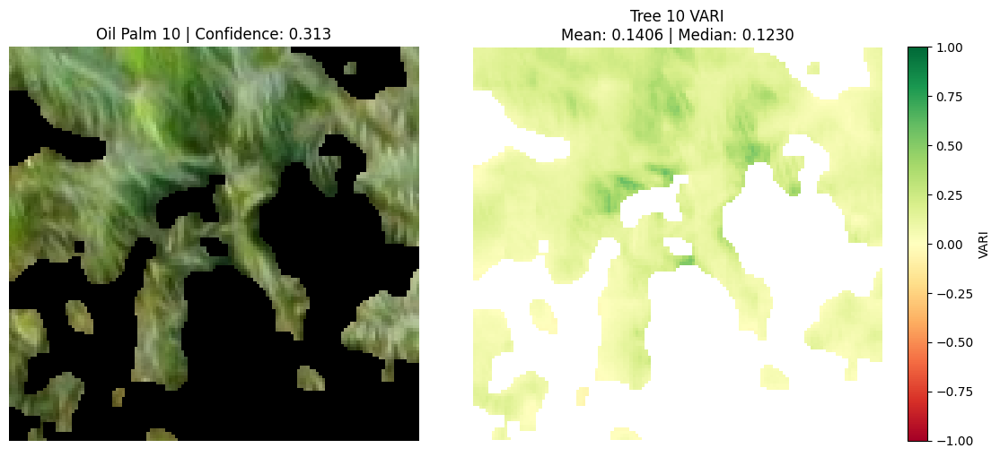

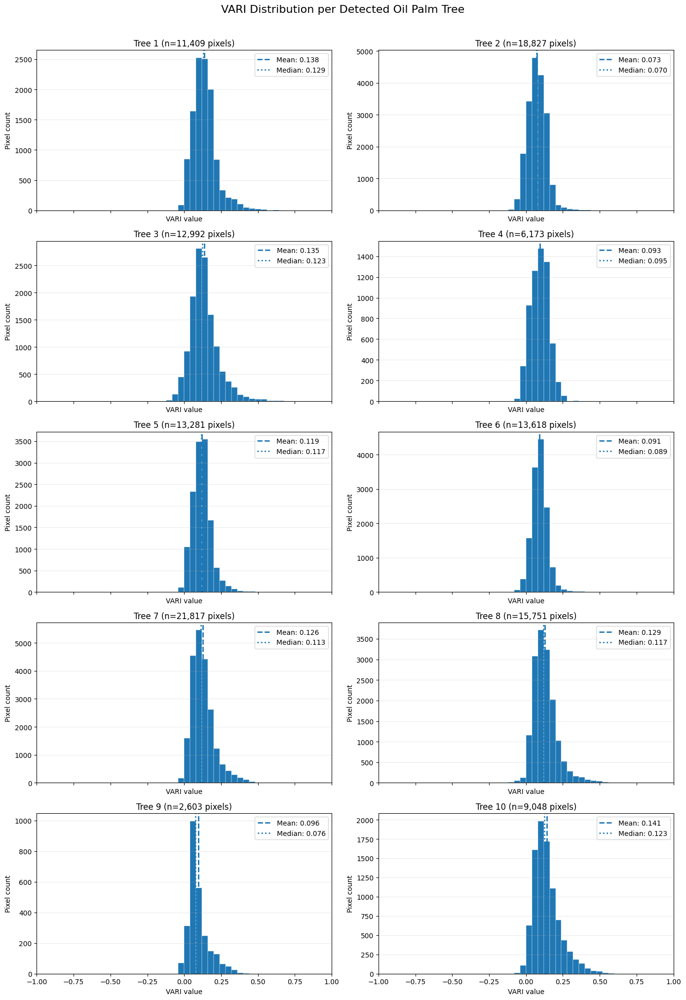

In [8]:
import cv2
import numpy as np
import coremltools as ct
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import io
import base64
from IPython.display import HTML, display

IMAGE_PATH = "S2_426.png"
MODEL_PATH = "yolo26m-krops-v0.1.mlpackage"

CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.45


# --------------------------------------------------
# Helper Functions: IoU and NMS
# --------------------------------------------------

def iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    inter_w = max(0, x2 - x1)
    inter_h = max(0, y2 - y1)
    inter_area = inter_w * inter_h

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - inter_area
    return inter_area / union if union > 0 else 0


def nms(boxes, scores, iou_threshold=0.45):
    order = np.argsort(scores)[::-1]
    selected = []

    while len(order) > 0:
        i = order[0]
        selected.append(i)
        remaining = []

        for j in order[1:]:
            if iou(boxes[i], boxes[j]) <= iou_threshold:
                remaining.append(j)

        order = np.array(remaining)

    return selected


# --------------------------------------------------
# Step 1: Run ExG Segmentation
# --------------------------------------------------

def segment_vegetation_exg(image_path):
    image_bgr = cv2.imread(image_path)
    if image_bgr is None:
        raise ValueError(f"Could not load image from {image_path}. Check the path.")

    b, g, r = cv2.split(image_bgr)
    exg = (2 * g.astype(np.float32)) - r.astype(np.float32) - b.astype(np.float32)

    exg_normalized = cv2.normalize(exg, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)
    exg_uint8 = np.clip(exg_normalized, 0, 255).astype(np.uint8)

    _, binary_mask = cv2.threshold(exg_uint8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    kernel = np.ones((3, 3), np.uint8)
    binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_OPEN, kernel, iterations=1)
    binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel, iterations=1)

    segmented_plant = cv2.bitwise_and(image_bgr, image_bgr, mask=binary_mask)
    return binary_mask, segmented_plant, image_bgr

print("Running ExG Segmentation...")
exg_mask, exg_segmented_bgr, original_bgr = segment_vegetation_exg(IMAGE_PATH)
exg_rgb = cv2.cvtColor(exg_segmented_bgr, cv2.COLOR_BGR2RGB)
original_height, original_width = original_bgr.shape[:2]

# Plot ExG Inline
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(exg_mask, cmap='gray')
axes[0].set_title("ExG Binary Mask (Otsu)", fontsize=12, fontweight='bold')
axes[0].axis('off')
axes[1].imshow(exg_rgb)
axes[1].set_title("ExG Segmented Plant Result", fontsize=12, fontweight='bold')
axes[1].axis('off')
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Step 2: Run CoreML Detection on ExG Output & Save Boxes
# --------------------------------------------------

saved_boxes = []
saved_scores = []

try:
    print(f"Loading CoreML model from {MODEL_PATH}...")
    model = ct.models.MLModel(MODEL_PATH)
    input_name = list(model.input_description)[0]
    
    image_exg_pil = Image.fromarray(exg_rgb).convert("RGB")
    input_image = image_exg_pil.resize((640, 640))

    print("Running inference on ExG segmented image...")
    prediction = model.predict({input_name: input_image})
    
    output_key = list(prediction.keys())[0]
    raw = np.asarray(prediction[output_key])

    predictions = raw[0].T
    temp_boxes = []
    temp_scores = []

    for pred in predictions:
        cx, cy, w, h, confidence = pred
        if confidence < CONF_THRESHOLD:
            continue

        x1 = (cx - w / 2) / 640
        y1 = (cy - h / 2) / 640
        x2 = (cx + w / 2) / 640
        y2 = (cy + h / 2) / 640

        temp_boxes.append([max(0, min(1, x1)), max(0, min(1, y1)), max(0, min(1, x2)), max(0, min(1, y2))])
        temp_scores.append(float(confidence))

    if temp_boxes:
        selected = nms(temp_boxes, temp_scores, IOU_THRESHOLD)
        saved_boxes = [temp_boxes[i] for i in selected]
        saved_scores = [temp_scores[i] for i in selected]

    print(f"Saved {len(saved_boxes)} valid detection boxes from ExG inference.")

except Exception as e:
    print(f"\n[Execution Note]: {e}")
    print("Tip: CoreML native prediction (`model.predict()`) requires running inside a macOS environment.")


# --------------------------------------------------
# Step 3: Calculate VARI from Original RGB Image
# --------------------------------------------------

print("\nCalculating VARI from original RGB image...")

# OpenCV loads the original image in BGR order
b_original, g_original, r_original = cv2.split(original_bgr)

# Convert to float to avoid integer arithmetic issues
b_f = b_original.astype(np.float32)
g_f = g_original.astype(np.float32)
r_f = r_original.astype(np.float32)

# VARI = (G - R) / (G + R - B)
denominator = g_f + r_f - b_f

vari_map = np.full(denominator.shape, np.nan, dtype=np.float32)

valid_pixels = denominator != 0

np.divide(
    g_f - r_f,
    denominator,
    out=vari_map,
    where=valid_pixels
)

# --------------------------------------------------
# Step 4: Calculate VARI for Each Detected Tree
# --------------------------------------------------

print("\nCalculating VARI for each detected oil palm...")

tree_results = []

# Use original image for the crops
original_rgb = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)

for idx, (box, score) in enumerate(zip(saved_boxes, saved_scores)):

    # Bounding box coordinates are normalized to [0, 1]
    x1, y1, x2, y2 = box

    # Convert to original image pixel coordinates
    px1 = max(0, int(x1 * original_width))
    py1 = max(0, int(y1 * original_height))
    px2 = min(original_width, int(x2 * original_width))
    py2 = min(original_height, int(y2 * original_height))

    if px2 <= px1 or py2 <= py1:
        continue

    # Crop the VARI map and ExG mask for this tree
    tree_vari = vari_map[py1:py2, px1:px2]
    tree_mask = exg_mask[py1:py2, px1:px2]

    # Only use pixels identified as vegetation by ExG
    valid_tree_pixels = (
        (tree_mask > 0) &
        np.isfinite(tree_vari)
    )

    values = tree_vari[valid_tree_pixels]

    if values.size == 0:
        mean_vari = np.nan
        median_vari = np.nan
        std_vari = np.nan
    else:
        mean_vari = float(np.mean(values))
        median_vari = float(np.median(values))
        std_vari = float(np.std(values))

    tree_results.append({
        "tree_id": idx + 1,
        "confidence": float(score),
        "bbox": (px1, py1, px2, py2),
        "vegetation_pixels": int(values.size),
        "mean_vari": mean_vari,
        "median_vari": median_vari,
        "std_vari": std_vari,
    })

# --------------------------------------------------
# Step 5: Display Annotated Core ML Detection Image
# --------------------------------------------------

print("\n--- Core ML Annotated Detection Image ---")

# Start with the ORIGINAL RGB image, not the ExG-segmented image
annotated_image = Image.fromarray(exg_rgb)
draw = ImageDraw.Draw(annotated_image)

for idx, (box, score) in enumerate(zip(saved_boxes, saved_scores)):

    x1, y1, x2, y2 = box

    # Convert normalized coordinates to original image coordinates
    px1 = max(0, int(x1 * original_width))
    py1 = max(0, int(y1 * original_height))
    px2 = min(original_width, int(x2 * original_width))
    py2 = min(original_height, int(y2 * original_height))

    # Draw bounding box
    draw.rectangle(
        [px1, py1, px2, py2],
        outline="red",
        width=3
    )

    # Label and confidence score
    label = f"Oil Palm {idx + 1}: {score:.2f}"

    # Draw label above the box where possible
    text_y = max(0, py1 - 22)

    # Add a background for label readability
    text_bbox = draw.textbbox((px1, text_y), label)
    draw.rectangle(text_bbox, fill="red")

    draw.text(
        (px1, text_y),
        label,
        fill="white"
    )

# Display the annotated image
plt.figure(figsize=(16, 10))
plt.imshow(annotated_image)
plt.title(
    f"Core ML Oil Palm Detection — {len(saved_boxes)} Detections"
)
plt.axis("off")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# Step 6: Visualize VARI for Each Detected Tree
# --------------------------------------------------

print(f"\nDetected trees with results: {len(tree_results)}")

for result in tree_results:

    tree_id = result["tree_id"]
    px1, py1, px2, py2 = result["bbox"]

    # Crop original RGB image and corresponding VARI map
    tree_rgb = exg_rgb[py1:py2, px1:px2]
    tree_vari = vari_map[py1:py2, px1:px2]
    tree_mask = exg_mask[py1:py2, px1:px2]

    # Hide pixels outside the vegetation mask
    tree_vari_display = np.where(
        (tree_mask > 0) & np.isfinite(tree_vari),
        tree_vari,
        np.nan
    )

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(tree_rgb)
    axes[0].set_title(
        f"Oil Palm {tree_id} | Confidence: {result['confidence']:.3f}"
    )
    axes[0].axis("off")

    im = axes[1].imshow(
        tree_vari_display,
        cmap="RdYlGn",
        vmin=-1,
        vmax=1
    )

    axes[1].set_title(
        f"Tree {tree_id} VARI\n"
        f"Mean: {result['mean_vari']:.4f} | "
        f"Median: {result['median_vari']:.4f}"
    )
    axes[1].axis("off")

    fig.colorbar(im, ax=axes[1], label="VARI")
    plt.tight_layout()
    plt.show()

# ==========================================
# STEP 7: VARI DISTRIBUTION PER DETECTED TREE
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

tree_vari_distributions = []

for idx, box in enumerate(saved_boxes):
    x1, y1, x2, y2 = box

    # Convert normalized bounding box to pixel coordinates
    px1 = max(0, int(x1 * original_width))
    py1 = max(0, int(y1 * original_height))
    px2 = min(original_width, int(x2 * original_width))
    py2 = min(original_height, int(y2 * original_height))

    # Crop VARI map and vegetation mask
    tree_vari = vari_map[py1:py2, px1:px2]
    tree_mask = exg_mask[py1:py2, px1:px2]

    # Include only vegetation pixels with finite VARI values
    valid_pixels = (
        (tree_mask > 0) &
        np.isfinite(tree_vari)
    )

    values = tree_vari[valid_pixels]

    if values.size == 0:
        print(f"Tree {idx + 1}: No valid VARI pixels.")
        continue

    tree_vari_distributions.append({
        "tree_id": idx + 1,
        "values": values,
        "mean": np.mean(values),
        "median": np.median(values),
        "std": np.std(values),
    })


# ==========================================
# PLOT: HISTOGRAM FOR EACH TREE
# ==========================================

number_of_trees = len(tree_vari_distributions)

if number_of_trees == 0:
    print("No trees contain valid VARI pixels.")
else:
    cols = 2
    rows = (number_of_trees + cols - 1) // cols

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(14, 4 * rows),
        sharex=True,
        sharey=False,
        squeeze=False,
    )

    axes = axes.flatten()

    for ax, result in zip(axes, tree_vari_distributions):
        values = result["values"]

        ax.hist(
            values,
            bins=50,
            range=(-1, 1),
            edgecolor="white",
            linewidth=0.3,
        )

        ax.axvline(
            result["mean"],
            linestyle="--",
            linewidth=2,
            label=f"Mean: {result['mean']:.3f}",
        )

        ax.axvline(
            result["median"],
            linestyle=":",
            linewidth=2,
            label=f"Median: {result['median']:.3f}",
        )

        ax.set_title(
            f"Tree {result['tree_id']} "
            f"(n={len(values):,} pixels)"
        )
        ax.set_xlabel("VARI value")
        ax.set_ylabel("Pixel count")
        ax.set_xlim(-1, 1)
        ax.grid(axis="y", alpha=0.25)
        ax.legend()

    # Hide unused subplot axes
    for ax in axes[number_of_trees:]:
        ax.set_visible(False)

    fig.suptitle(
        "VARI Distribution per Detected Oil Palm Tree",
        fontsize=16,
        y=1.01,
    )

    plt.tight_layout()
    plt.show()    

Running ExG Segmentation...


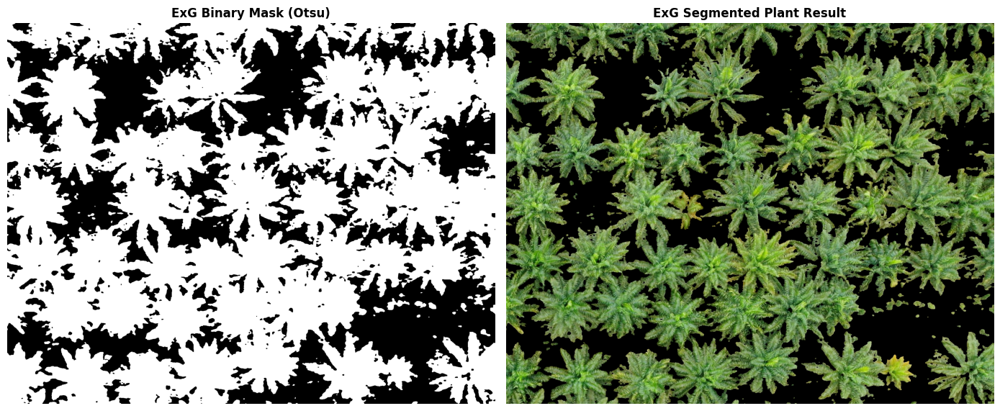

Loading CoreML model from yolo26m-krops-v0.1.mlpackage...
Running inference on ExG segmented image...
Saved 37 valid detection boxes from ExG inference.

Calculating VARI from original RGB image...

Calculating VARI for each detected oil palm...

--- Core ML Annotated Detection Image ---


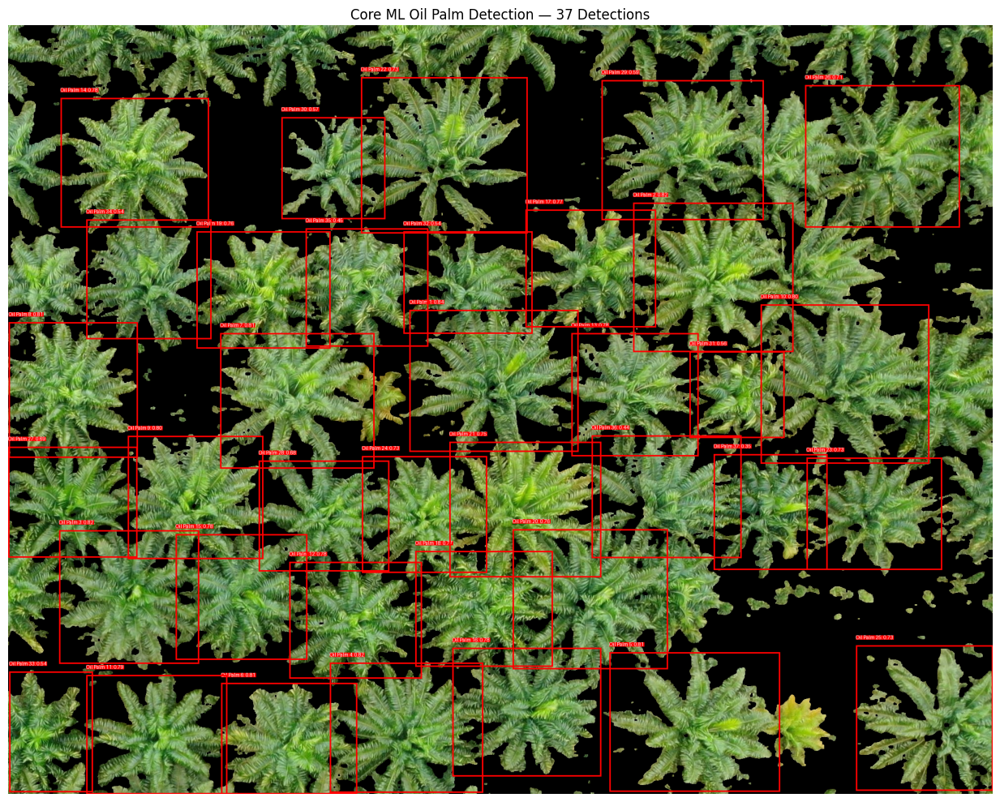


Detected trees with results: 37


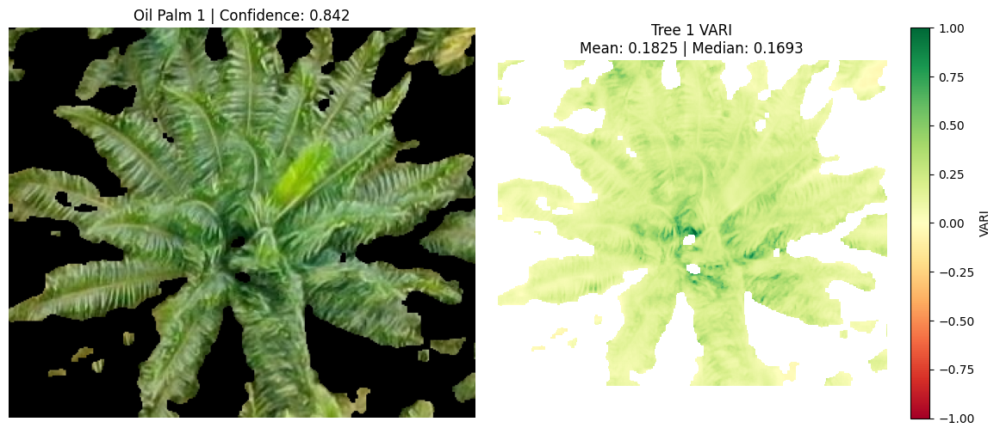

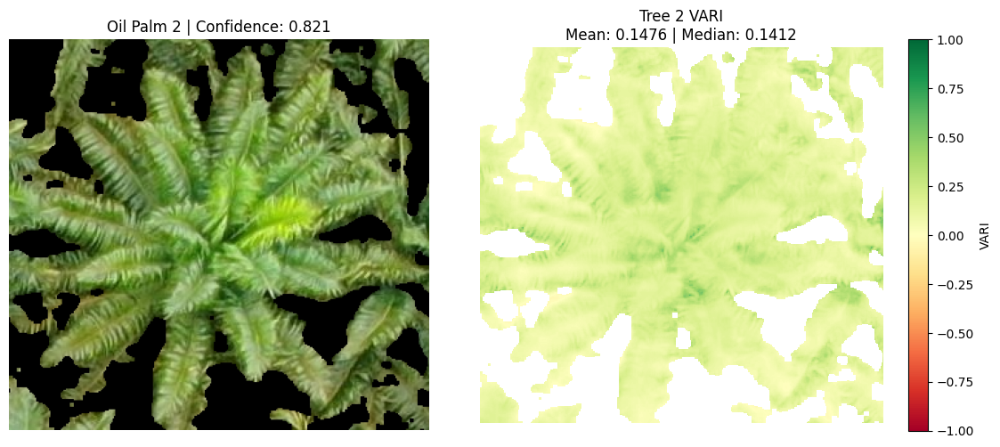

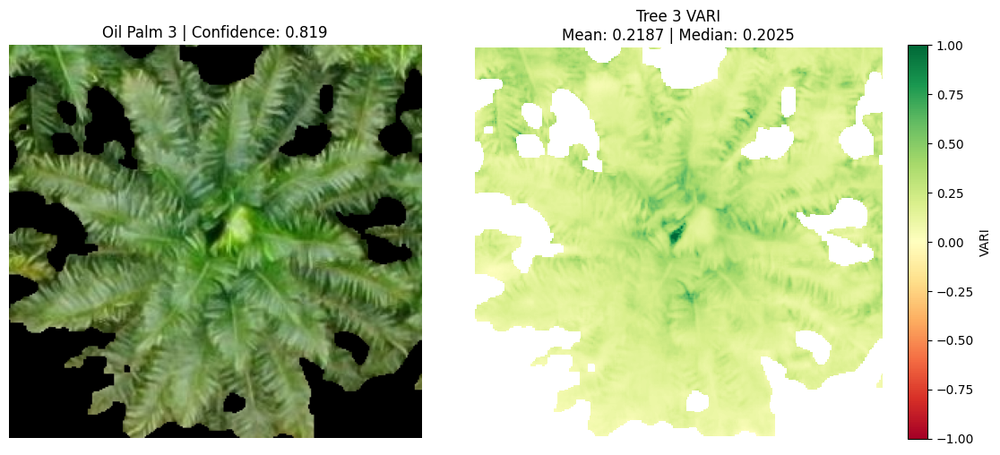

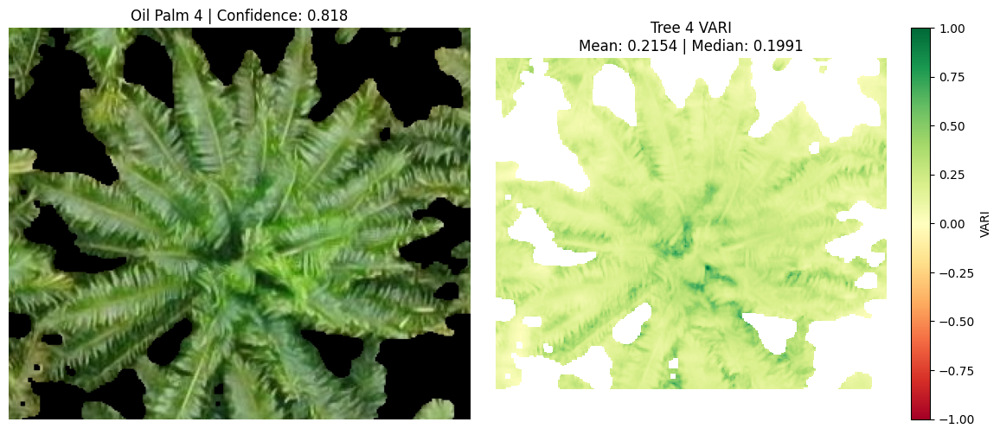

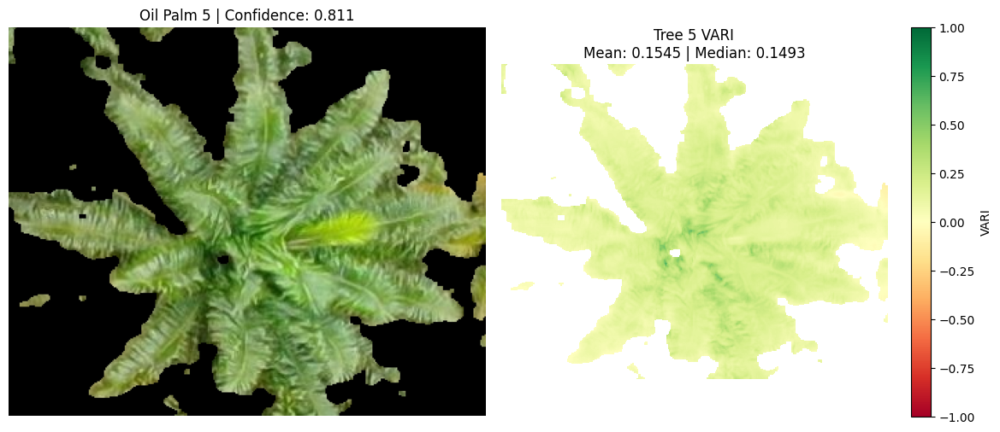

...

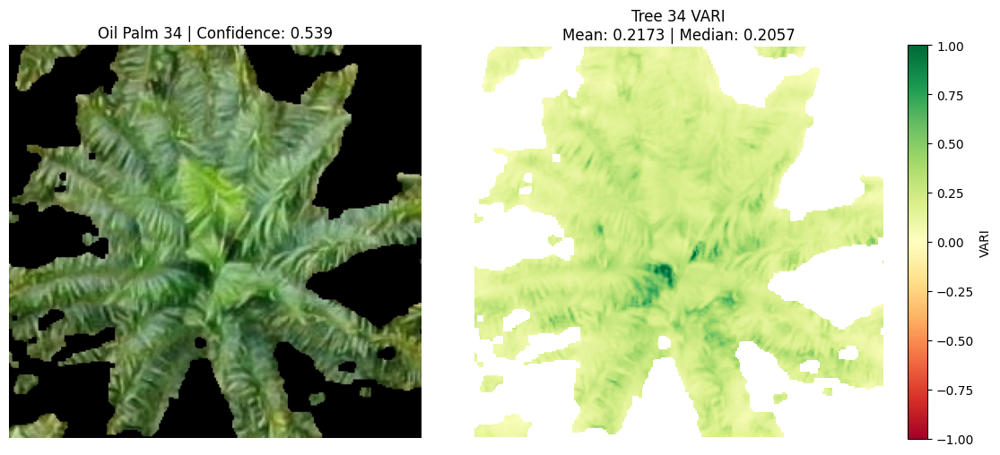

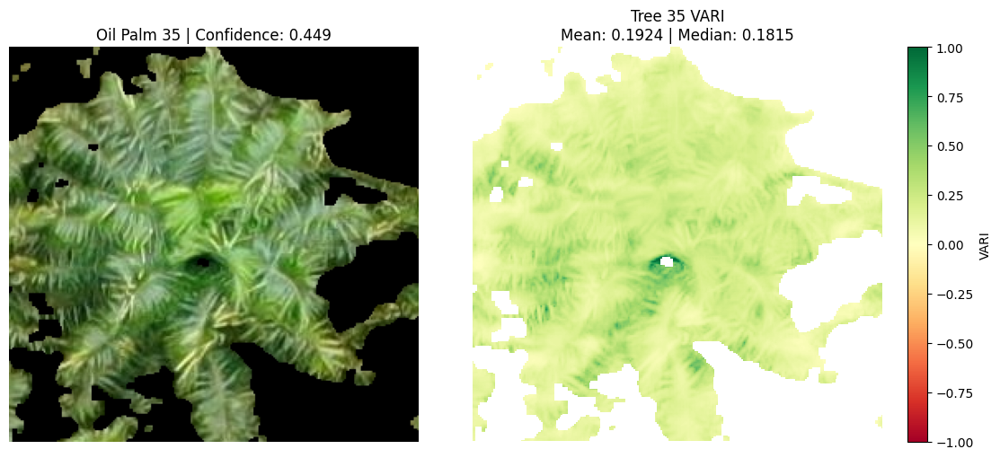

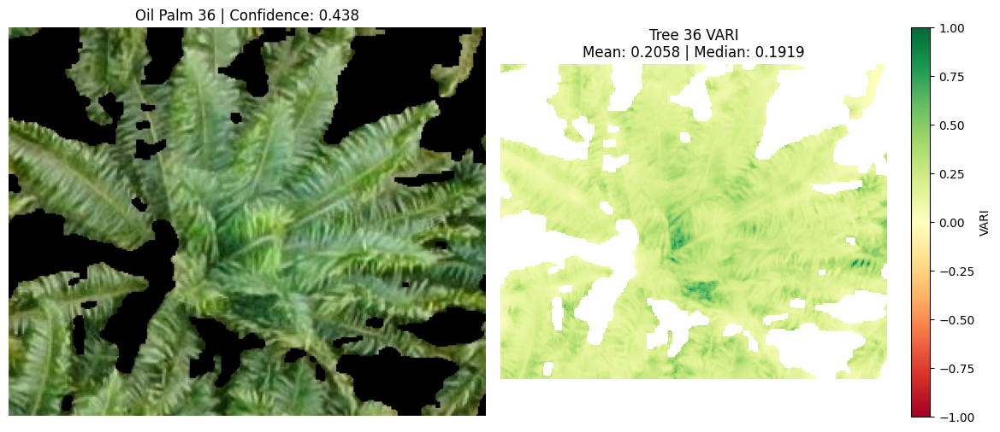

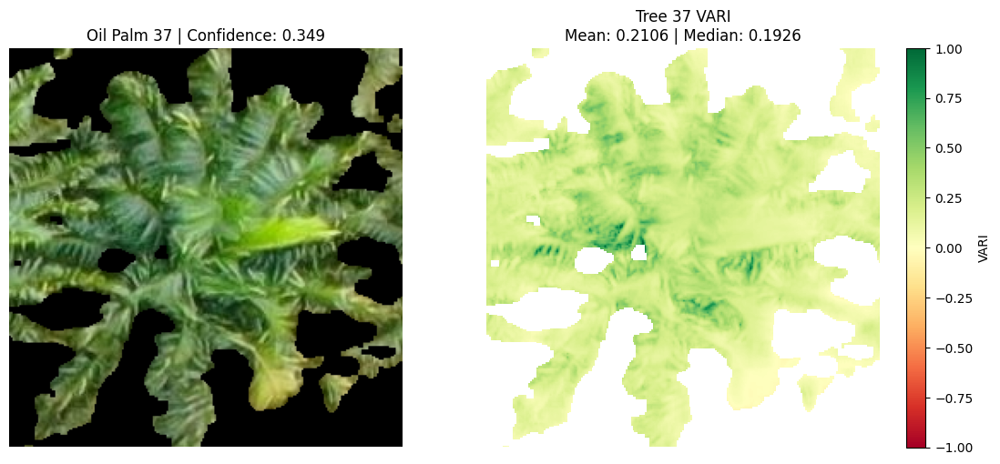

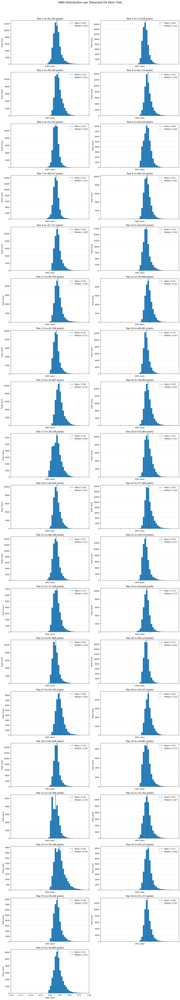

In [10]:
import cv2
import numpy as np
import coremltools as ct
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import io
import base64
from IPython.display import HTML, display

IMAGE_PATH = "DJI_10 copy.jpg"
MODEL_PATH = "yolo26m-krops-v0.1.mlpackage"

CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.45


# --------------------------------------------------
# Helper Functions: IoU and NMS
# --------------------------------------------------

def iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    inter_w = max(0, x2 - x1)
    inter_h = max(0, y2 - y1)
    inter_area = inter_w * inter_h

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - inter_area
    return inter_area / union if union > 0 else 0


def nms(boxes, scores, iou_threshold=0.45):
    order = np.argsort(scores)[::-1]
    selected = []

    while len(order) > 0:
        i = order[0]
        selected.append(i)
        remaining = []

        for j in order[1:]:
            if iou(boxes[i], boxes[j]) <= iou_threshold:
                remaining.append(j)

        order = np.array(remaining)

    return selected


# --------------------------------------------------
# Step 1: Run ExG Segmentation
# --------------------------------------------------

def segment_vegetation_exg(image_path):
    image_bgr = cv2.imread(image_path)
    if image_bgr is None:
        raise ValueError(f"Could not load image from {image_path}. Check the path.")

    b, g, r = cv2.split(image_bgr)
    exg = (2 * g.astype(np.float32)) - r.astype(np.float32) - b.astype(np.float32)

    exg_normalized = cv2.normalize(exg, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)
    exg_uint8 = np.clip(exg_normalized, 0, 255).astype(np.uint8)

    _, binary_mask = cv2.threshold(exg_uint8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    kernel = np.ones((3, 3), np.uint8)
    binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_OPEN, kernel, iterations=1)
    binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel, iterations=1)

    segmented_plant = cv2.bitwise_and(image_bgr, image_bgr, mask=binary_mask)
    return binary_mask, segmented_plant, image_bgr

print("Running ExG Segmentation...")
exg_mask, exg_segmented_bgr, original_bgr = segment_vegetation_exg(IMAGE_PATH)
exg_rgb = cv2.cvtColor(exg_segmented_bgr, cv2.COLOR_BGR2RGB)
original_height, original_width = original_bgr.shape[:2]

# Plot ExG Inline
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(exg_mask, cmap='gray')
axes[0].set_title("ExG Binary Mask (Otsu)", fontsize=12, fontweight='bold')
axes[0].axis('off')
axes[1].imshow(exg_rgb)
axes[1].set_title("ExG Segmented Plant Result", fontsize=12, fontweight='bold')
axes[1].axis('off')
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Step 2: Run CoreML Detection on ExG Output & Save Boxes
# --------------------------------------------------

saved_boxes = []
saved_scores = []

try:
    print(f"Loading CoreML model from {MODEL_PATH}...")
    model = ct.models.MLModel(MODEL_PATH)
    input_name = list(model.input_description)[0]
    
    image_exg_pil = Image.fromarray(exg_rgb).convert("RGB")
    input_image = image_exg_pil.resize((640, 640))

    print("Running inference on ExG segmented image...")
    prediction = model.predict({input_name: input_image})
    
    output_key = list(prediction.keys())[0]
    raw = np.asarray(prediction[output_key])

    predictions = raw[0].T
    temp_boxes = []
    temp_scores = []

    for pred in predictions:
        cx, cy, w, h, confidence = pred
        if confidence < CONF_THRESHOLD:
            continue

        x1 = (cx - w / 2) / 640
        y1 = (cy - h / 2) / 640
        x2 = (cx + w / 2) / 640
        y2 = (cy + h / 2) / 640

        temp_boxes.append([max(0, min(1, x1)), max(0, min(1, y1)), max(0, min(1, x2)), max(0, min(1, y2))])
        temp_scores.append(float(confidence))

    if temp_boxes:
        selected = nms(temp_boxes, temp_scores, IOU_THRESHOLD)
        saved_boxes = [temp_boxes[i] for i in selected]
        saved_scores = [temp_scores[i] for i in selected]

    print(f"Saved {len(saved_boxes)} valid detection boxes from ExG inference.")

except Exception as e:
    print(f"\n[Execution Note]: {e}")
    print("Tip: CoreML native prediction (`model.predict()`) requires running inside a macOS environment.")


# --------------------------------------------------
# Step 3: Calculate VARI from Original RGB Image
# --------------------------------------------------

print("\nCalculating VARI from original RGB image...")

# OpenCV loads the original image in BGR order
b_original, g_original, r_original = cv2.split(original_bgr)

# Convert to float to avoid integer arithmetic issues
b_f = b_original.astype(np.float32)
g_f = g_original.astype(np.float32)
r_f = r_original.astype(np.float32)

# VARI = (G - R) / (G + R - B)
denominator = g_f + r_f - b_f

vari_map = np.full(denominator.shape, np.nan, dtype=np.float32)

valid_pixels = denominator != 0

np.divide(
    g_f - r_f,
    denominator,
    out=vari_map,
    where=valid_pixels
)

# --------------------------------------------------
# Step 4: Calculate VARI for Each Detected Tree
# --------------------------------------------------

print("\nCalculating VARI for each detected oil palm...")

tree_results = []

# Use original image for the crops
original_rgb = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)

for idx, (box, score) in enumerate(zip(saved_boxes, saved_scores)):

    # Bounding box coordinates are normalized to [0, 1]
    x1, y1, x2, y2 = box

    # Convert to original image pixel coordinates
    px1 = max(0, int(x1 * original_width))
    py1 = max(0, int(y1 * original_height))
    px2 = min(original_width, int(x2 * original_width))
    py2 = min(original_height, int(y2 * original_height))

    if px2 <= px1 or py2 <= py1:
        continue

    # Crop the VARI map and ExG mask for this tree
    tree_vari = vari_map[py1:py2, px1:px2]
    tree_mask = exg_mask[py1:py2, px1:px2]

    # Only use pixels identified as vegetation by ExG
    valid_tree_pixels = (
        (tree_mask > 0) &
        np.isfinite(tree_vari)
    )

    values = tree_vari[valid_tree_pixels]

    if values.size == 0:
        mean_vari = np.nan
        median_vari = np.nan
        std_vari = np.nan
    else:
        mean_vari = float(np.mean(values))
        median_vari = float(np.median(values))
        std_vari = float(np.std(values))

    tree_results.append({
        "tree_id": idx + 1,
        "confidence": float(score),
        "bbox": (px1, py1, px2, py2),
        "vegetation_pixels": int(values.size),
        "mean_vari": mean_vari,
        "median_vari": median_vari,
        "std_vari": std_vari,
    })

# --------------------------------------------------
# Step 5: Display Annotated Core ML Detection Image
# --------------------------------------------------

print("\n--- Core ML Annotated Detection Image ---")

# Start with the ORIGINAL RGB image, not the ExG-segmented image
annotated_image = Image.fromarray(exg_rgb)
draw = ImageDraw.Draw(annotated_image)

for idx, (box, score) in enumerate(zip(saved_boxes, saved_scores)):

    x1, y1, x2, y2 = box

    # Convert normalized coordinates to original image coordinates
    px1 = max(0, int(x1 * original_width))
    py1 = max(0, int(y1 * original_height))
    px2 = min(original_width, int(x2 * original_width))
    py2 = min(original_height, int(y2 * original_height))

    # Draw bounding box
    draw.rectangle(
        [px1, py1, px2, py2],
        outline="red",
        width=3
    )

    # Label and confidence score
    label = f"Oil Palm {idx + 1}: {score:.2f}"

    # Draw label above the box where possible
    text_y = max(0, py1 - 22)

    # Add a background for label readability
    text_bbox = draw.textbbox((px1, text_y), label)
    draw.rectangle(text_bbox, fill="red")

    draw.text(
        (px1, text_y),
        label,
        fill="white"
    )

# Display the annotated image
plt.figure(figsize=(16, 10))
plt.imshow(annotated_image)
plt.title(
    f"Core ML Oil Palm Detection — {len(saved_boxes)} Detections"
)
plt.axis("off")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# Step 6: Visualize VARI for Each Detected Tree
# --------------------------------------------------

print(f"\nDetected trees with results: {len(tree_results)}")

for result in tree_results:

    tree_id = result["tree_id"]
    px1, py1, px2, py2 = result["bbox"]

    # Crop original RGB image and corresponding VARI map
    tree_rgb = exg_rgb[py1:py2, px1:px2]
    tree_vari = vari_map[py1:py2, px1:px2]
    tree_mask = exg_mask[py1:py2, px1:px2]

    # Hide pixels outside the vegetation mask
    tree_vari_display = np.where(
        (tree_mask > 0) & np.isfinite(tree_vari),
        tree_vari,
        np.nan
    )

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(tree_rgb)
    axes[0].set_title(
        f"Oil Palm {tree_id} | Confidence: {result['confidence']:.3f}"
    )
    axes[0].axis("off")

    im = axes[1].imshow(
        tree_vari_display,
        cmap="RdYlGn",
        vmin=-1,
        vmax=1
    )

    axes[1].set_title(
        f"Tree {tree_id} VARI\n"
        f"Mean: {result['mean_vari']:.4f} | "
        f"Median: {result['median_vari']:.4f}"
    )
    axes[1].axis("off")

    fig.colorbar(im, ax=axes[1], label="VARI")
    plt.tight_layout()
    plt.show()

# ==========================================
# STEP 7: VARI DISTRIBUTION PER DETECTED TREE
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

tree_vari_distributions = []

for idx, box in enumerate(saved_boxes):
    x1, y1, x2, y2 = box

    # Convert normalized bounding box to pixel coordinates
    px1 = max(0, int(x1 * original_width))
    py1 = max(0, int(y1 * original_height))
    px2 = min(original_width, int(x2 * original_width))
    py2 = min(original_height, int(y2 * original_height))

    # Crop VARI map and vegetation mask
    tree_vari = vari_map[py1:py2, px1:px2]
    tree_mask = exg_mask[py1:py2, px1:px2]

    # Include only vegetation pixels with finite VARI values
    valid_pixels = (
        (tree_mask > 0) &
        np.isfinite(tree_vari)
    )

    values = tree_vari[valid_pixels]

    if values.size == 0:
        print(f"Tree {idx + 1}: No valid VARI pixels.")
        continue

    tree_vari_distributions.append({
        "tree_id": idx + 1,
        "values": values,
        "mean": np.mean(values),
        "median": np.median(values),
        "std": np.std(values),
    })


# ==========================================
# PLOT: HISTOGRAM FOR EACH TREE
# ==========================================

number_of_trees = len(tree_vari_distributions)

if number_of_trees == 0:
    print("No trees contain valid VARI pixels.")
else:
    cols = 2
    rows = (number_of_trees + cols - 1) // cols

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(14, 4 * rows),
        sharex=True,
        sharey=False,
        squeeze=False,
    )

    axes = axes.flatten()

    for ax, result in zip(axes, tree_vari_distributions):
        values = result["values"]

        ax.hist(
            values,
            bins=50,
            range=(-1, 1),
            edgecolor="white",
            linewidth=0.3,
        )

        ax.axvline(
            result["mean"],
            linestyle="--",
            linewidth=2,
            label=f"Mean: {result['mean']:.3f}",
        )

        ax.axvline(
            result["median"],
            linestyle=":",
            linewidth=2,
            label=f"Median: {result['median']:.3f}",
        )

        ax.set_title(
            f"Tree {result['tree_id']} "
            f"(n={len(values):,} pixels)"
        )
        ax.set_xlabel("VARI value")
        ax.set_ylabel("Pixel count")
        ax.set_xlim(-1, 1)
        ax.grid(axis="y", alpha=0.25)
        ax.legend()

    # Hide unused subplot axes
    for ax in axes[number_of_trees:]:
        ax.set_visible(False)

    fig.suptitle(
        "VARI Distribution per Detected Oil Palm Tree",
        fontsize=16,
        y=1.01,
    )

    plt.tight_layout()
    plt.show()    